<div align="center">

<h2 style="margin-bottom: 0px;">Final Exam MST 0641</h2>

<h3 style="margin-top: 5px; margin-bottom: 0px;">
Numerical Methods in Python with Applications
</h3>

<h4 style="margin-top: 5px;">
Fall 2026
</h4>

</div>

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"    # macOS: allow PyTorch's and NumPy's OpenMP runtimes together

import torch
import torch.nn as nn
import time
from typing import NamedTuple
import numpy as np
import matplotlib.pyplot as plt

import scipy.sparse as sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import fsolve, brentq
from scipy.integrate import solve_ivp, solve_bvp
from scipy.stats import norm

### Add group member here:

ID 1: XXXX

ID 2: XXXX

## Instructions

You can work in groups of up to two students. Please rename this notebook as <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">G_ID1_ID2.ipynb</code>, where ID1 and ID2 are the ID numbers of the students in the group, and write the ID number of each student in the cell above.

You cannot talk to other groups during the exam. You may use AI tools (for example a chat assistant or a code assistant); you are responsible for every line you submit and must be able to explain it.

Write your code in the empty cells below each part and execute every cell, so that the notebook you hand in shows your output. You may add cells and comments to your code if necessary. Be concise: do not print long arrays or tables.

The three questions cover three methods of the course: boundary value problems solved by shooting (Question 1), finite differences and deep learning for an HJB equation (Question 2), and value function iteration with a discrete choice (Question 3). Each question states the **Model** and then the **Numerical methods** you must use; the parts ask for the functions that implement them.

Some computations take a few minutes; the text says which, so that you can plan your time.

Finally, feel free to make assumptions about parameter values or missing information so the problem works; state them in a comment.

Good luck!

# Question 1. A capital tax in an open economy (30 points)

In this exercise you compute the transition of an open economy after a permanent rise in the capital tax. You solve the saddle path by shooting with bisection, compute consumption by quadrature, verify both with solve_bvp, and compare a static with a dynamic Laffer curve.

A country raises its capital income tax from 30% to 40% for good. Capital cannot leave the country, but households borrow and lend abroad at a fixed world interest rate. What happens to capital, to how intensively it is used, to foreign assets and to consumption? And how much revenue does the tax raise once the transition is counted?

**Model.**

*Technology.* Capital $k$ is used at intensity $m$ (utilization), so capital services are $mk$. With one unit of labour,

$$
y=A\,(mk)^{\beta},\qquad r^k=\beta A\,(mk)^{\beta-1},\qquad w=(1-\beta)\,y .
$$

Using capital harder makes it depreciate faster, and investing away from the normal rate $z$ is costly:

$$
\delta(m)=\frac{\chi_0\,m^{\chi_1}}{\chi_1},\qquad \Phi(i,k)=\frac{\eta}{2}\Big(\frac ik-z\Big)^2k .
$$

*Household.* It owns the capital, holds foreign bonds $b$ at the world rate $r$, pays the tax $\tau$ on capital income net of an allowance $\theta\bar\delta k$, and receives a lump-sum transfer $e$:

$$
\max_{c,i,m}\int_0^\infty e^{-\rho t}u(c_t)\,dt\qquad\text{s.t.}\qquad
\begin{cases}
\dot b=rb+w+(1-\tau)\,r^kmk+\tau\theta\bar\delta k+e-c-i-\Phi(i,k),\\[4pt]
\dot k=i-\delta(m)\,k .
\end{cases}
$$

*Optimality.* With the current-value Hamiltonian

$$
\mathcal H=u(c)+\lambda\big[rb+w+(1-\tau)r^kmk+\tau\theta\bar\delta k+e-c-i-\Phi\big]+\lambda q\big[i-\delta(m)k\big],
$$

the first-order conditions for $c$, $i$ and $m$ are

$$
u'(c)=\lambda,\qquad 1+\eta\Big(\frac ik-z\Big)=q,\qquad (1-\tau)\,r^k=q\,\delta'(m),
$$

and the costate equations are $\dot\lambda=(\rho-r)\lambda$ and

$$
\dot q=\big(r+\delta(m)\big)q-(1-\tau)r^km-\tau\theta\bar\delta-(q-1)z-\frac{(q-1)^2}{2\eta}.
$$

*Equilibrium.* The world rate equals the discount rate, $r=\rho$, so $\lambda$ and $c$ are constant. The static conditions give investment and utilization as functions of $(k,q)$:

$$
\frac ik=z+\frac{q-1}{\eta},\qquad m^{\beta-\chi_1}=\frac{q\,\chi_0\,k^{1-\beta}}{(1-\tau)\beta A}.
$$

At $t=0$ the tax rises from $\tau_0=0.30$ to $\tau_1=0.40$ for good. The economy starts in the old steady state, $k^\star(\tau_0)$, with no foreign assets:

$$
\left\{\begin{array}{lll}
\dot k(t)=i-\delta(m)\,k & & \text{capital}\\[4pt]
\dot q(t)=\big(r+\delta(m)\big)q-(1-\tau_1)r^km-\tau_1\theta\bar\delta-(q-1)z-\dfrac{(q-1)^2}{2\eta} & & \text{Tobin's }q\\[10pt]
\dot b(t)=rb+w+(1-\tau_1)r^kmk+\tau_1\theta\bar\delta k+e-c-i-\Phi & & \text{current account}\\[10pt]
k(0)=k^\star(\tau_0) & t=0 & \text{initial, old steady state}\\[3pt]
b(0)=0 & t=0 & \text{initial}\\[3pt]
\displaystyle\lim_{t\to\infty}(k,q)=\big(k^\star,q^\star\big)(\tau_1) & t\to\infty & \text{terminal, new steady state}\\[3pt]
\displaystyle\lim_{t\to\infty}e^{-rt}\,b(t)=0 & t\to\infty & \text{terminal, budget}
\end{array}\right.
$$

The $(k,q)$ block does not involve $b$ or $c$: it is a saddle path in two dimensions with one jump variable, $q$. The budget constraint then pins the constant $c$.

**Numerical methods.** This is a boundary value problem (Lecture 11): three ODEs with two conditions at $t=0$ and two at $t=\infty$. Two numbers are unknown, the jump $q(0)$ and the constant $c$, and the system is solved block by block.

1. Steady states, part (a). Solve $\dot k=\dot q=0$ for $(k^\star,q^\star)$ with fsolve. Over a range of taxes use *continuation*: the steady state at one $\tau$ is the initial guess at the next.
2. Shooting on $q(0)$, part (b). Guess $q(0)$, integrate the $(k,q)$ block forward with solve_ivp, and bisect on the direction in which the path misses the new steady state:
$$
q(0)\ \text{too low}\ \Rightarrow\ k\ \text{falls through}\ k^\star(\tau_1),\qquad q(0)\ \text{too high}\ \Rightarrow\ k\ \text{turns up before reaching}\ k^\star(\tau_1).
$$
   This works because the $(k,q)$ block has one unstable root and one jump variable. The two cases are detected with terminal events of solve_ivp.
3. Quadrature, parts (c) and (d). A discounted integral along the path is computed with the trapezoid rule up to the exit time $t_e$ of the bisected path, plus the tail at the new steady-state value $f^\star$:
$$
\int_0^\infty e^{-rt}f(t)\,dt\approx\int_0^{t_e}e^{-rt}f(t)\,dt+e^{-rt_e}\,\frac{f^\star}{r}.
$$
   With $f=n$, net income, it gives consumption from the budget constraint; with $f$ the tax revenue it gives the present value of revenue.
4. solve_bvp from scipy, part (c), as a second method: the full system $(k,q,b)$ on $[0,T]$, with $c$ as an unknown parameter and the terminal conditions imposed at $T$.
5. Laffer curves, parts (a) and (d). The static curve uses method 1 at each $\tau$; the dynamic curve repeats methods 2 and 3 for each $\tau_1$.

**Parameters** (time in years). $\beta=0.39$, $A=1$, $r=\rho=0.04$, $\chi_1=1.5$, $\theta=0.5$, $\eta=10$, $\bar\delta=r/(\chi_1-1+\theta\tau_0)$, $\chi_0=\chi_1\bar\delta$, $z=\bar\delta$, and $e$ such that consumption in the old steady state is 1 ($e$ turns out negative: a lump-sum tax). With these values $m=q=1$ in the old steady state. The model is given below; <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">depreciation(u, m)</code> is $\delta(m)$ at utilization <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">u</code> (we write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">u</code> for utilization in code, since <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">m</code> is the model).

In [2]:
class CapitalTax(NamedTuple):
    β: float        # capital share
    A: float        # productivity
    r: float        # world interest rate (= discount rate)
    χ0: float       # depreciation level: δ(m) = χ0 m^χ1 / χ1
    χ1: float       # depreciation curvature
    θ: float        # depreciation allowance
    η: float        # investment adjustment cost
    δ_bar: float    # depreciation at m = 1
    z: float        # normal investment rate
    e: float        # lump-sum transfer (negative: a tax)
    τ0: float       # old capital tax
    τ1: float       # new capital tax


def create_capital_tax(β=0.39, A=1.0, r=0.04, χ1=1.5, θ=0.5, η=10.0, τ0=0.30, τ1=0.40):
    δ_bar = r / (χ1 - 1 + θ*τ0)
    χ0, z = χ1*δ_bar, δ_bar
    k_old = ((1 - τ0)*β*A/χ0)**(1/(1 - β))           # old steady state, where m = q = 1
    y_old = A*k_old**β
    e = 1 - ((1 - β)*y_old + (1 - τ0)*β*y_old + τ0*θ*δ_bar*k_old - z*k_old)   # c = 1 there
    return CapitalTax(β, A, r, χ0, χ1, θ, η, δ_bar, z, e, τ0, τ1)


def depreciation(u, m):
    "δ(m) = χ0 m^χ1 / χ1 at utilization u."
    return m.χ0 * u**m.χ1 / m.χ1


m1 = create_capital_tax()
print(m1)

CapitalTax(β=0.39, A=1.0, r=0.04, χ0=0.0923076923076923, χ1=1.5, θ=0.5, η=10.0, δ_bar=0.061538461538461535, z=0.061538461538461535, e=-0.45677791530352163, τ0=0.3, τ1=0.4)


**(a) Steady states and the static Laffer curve.** In a steady state $\dot k=\dot q=0$:

$$
z+\frac{q-1}{\eta}=\delta(m),\qquad \big(r+\delta(m)\big)q=(1-\tau)r^km+\tau\theta\bar\delta+(q-1)z+\frac{(q-1)^2}{2\eta},
$$

with $m=m(q,k)$ from the static condition and $r^k=\beta A(mk)^{\beta-1}$, both evaluated at $(k,q)$. At $\tau_0$ the closed form is $k^\star(\tau_0)=\big((1-\tau_0)\beta A/\chi_0\big)^{1/(1-\beta)}$, $q^\star=m^\star=1$. Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">utilization(q, k, tau, m)</code> returning $m(q,k)$ (the argument m is the model), and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">steady&#95;state(tau, m, guess)</code> that solves the two equations for $(k^\star,q^\star)$ with fsolve (xtol=1e-13) and returns $(k^\star,q^\star,m^\star)$. Then:

(i) Compute $(k^\star,q^\star,m^\star)$ at $\tau_0$ from the guess $(0.8\,k^\star(\tau_0),\,0.9)$, compare it with the closed form, and compute $(k^\star,q^\star,m^\star)$ at $\tau_1$ (guess: the solution at $\tau_0$).

(ii) Compute the stationary revenue $R(\tau)=\tau\big(r^km^\star-\theta\bar\delta\big)k^\star$ for $\tau\in\{0.30,0.35,\dots,0.90\}$ by continuation: the steady state at the previous $\tau$ is the guess at the next, starting from the steady state at $\tau_0$. Store the steady states in a dictionary keyed by $\tau$ (round the grid with np.round(..., 2)), since (d) reuses them. Plot $R(\tau)$ and report the revenue-maximizing tax on the grid.

(iii) Call fsolve directly on the two equations at $\tau\in\{0.70,0.75,0.90\}$ from the cold guess $(k^\star(\tau_0),1)$ with full_output=True. Report fsolve's exit flag (ier) and the $k$ returned, compare that $k$ with the guess and with $k^\star$ from continuation, and comment on the implications.

Closed form (k, q, utilization) = (5.9157224832, 1.0, 1.0)
Old steady state               = (5.9157224832, 1.0, 1.0)
New steady state               = (5.1515284464, 0.9689845523, 0.966111176)
Maximum old steady-state discrepancy = 2.665e-15
Static revenue maximum = 0.31383659 at tax 70%
Tax    ier       cold k      initial k   continued k   residual norm
0.70     5    5.91572248    5.91572248    2.57453046   4.196e-02
0.75     5    5.91572248    5.91572248    2.10273749   4.623e-02
0.90     5    5.91572248    5.91572248    0.67349774   5.710e-02


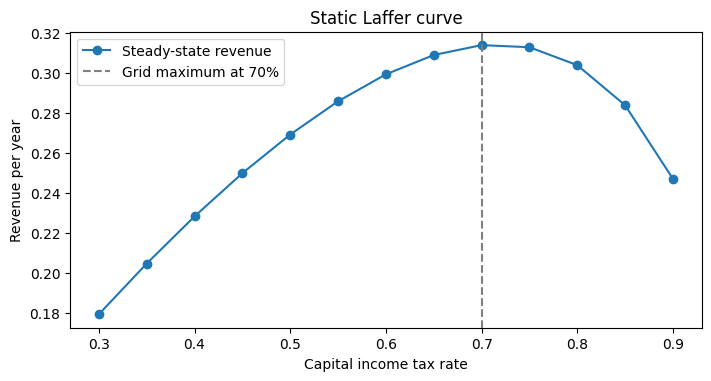

In [3]:
def utilization(q, k, tau, m):
    """Solve the utilization first-order condition at positive k and q."""
    ratio = q * m.χ0 * k**(1 - m.β) / ((1 - tau) * m.β * m.A)
    return ratio**(1 / (m.β - m.χ1))


def old_capital(m):
    return ((1 - m.τ0) * m.β * m.A / m.χ0)**(1 / (1 - m.β))


def capital_terms(k, q, tau, m):
    """Return utilization, investment per unit of capital, and gross rental income per unit."""
    u = utilization(q, k, tau, m)
    investment_rate = m.z + (q - 1) / m.η
    rental_per_capital = m.β * m.A * (u * k)**(m.β - 1) * u
    return u, investment_rate, rental_per_capital


def steady_residual(state, tau, m):
    k, q = state
    u, investment_rate, rental_per_capital = capital_terms(k, q, tau, m)
    dep = depreciation(u, m)
    q_dot = (
        (m.r + dep) * q - (1 - tau) * rental_per_capital
        - tau * m.θ * m.δ_bar - (q - 1) * m.z - (q - 1)**2 / (2 * m.η)
    )
    return investment_rate - dep, q_dot


def steady_state(tau, m, guess):
    """Return the positive steady-state capital, q and utilization."""
    state, info, flag, message = fsolve(
        steady_residual, guess, args=(tau, m), full_output=True, xtol=1e-13
    )
    error = np.max(np.abs(info["fvec"]))
    if not (np.all(state > 0) and error < 1e-11):
        raise RuntimeError(f"Steady state at tax {tau:g} failed (ier={flag}): {message}")
    k, q = state
    return k, q, utilization(q, k, tau, m)


def tax_revenue(k, q, tau, m):
    _, _, rental_per_capital = capital_terms(k, q, tau, m)
    return tau * (rental_per_capital - m.θ * m.δ_bar) * k


k_closed = old_capital(m1)
ss_old = steady_state(m1.τ0, m1, (0.8 * k_closed, 0.9))
ss_new = steady_state(m1.τ1, m1, ss_old[:2])
print("Closed form (k, q, utilization) =", tuple(map(float, np.round((k_closed, 1.0, 1.0), 10))))
print("Old steady state               =", tuple(map(float, np.round(ss_old, 10))))
print("New steady state               =", tuple(map(float, np.round(ss_new, 10))))
print(f"Maximum old steady-state discrepancy = {np.max(np.abs(np.array(ss_old) - [k_closed, 1, 1])):.3e}")

tax_grid = np.round(np.linspace(0.30, 0.90, 13), 2)
steady_states = {}
previous = ss_old
for tau in tax_grid:
    previous = steady_state(tau, m1, previous[:2])
    steady_states[tau] = previous
static_revenues = np.array([tax_revenue(*steady_states[tau][:2], tau, m1) for tau in tax_grid])
static_best = tax_grid[static_revenues.argmax()]
print(f"Static revenue maximum = {static_revenues.max():.8f} at tax {static_best:.0%}")

print("Tax    ier       cold k      initial k   continued k   residual norm")
for tau in (0.70, 0.75, 0.90):
    # The unrestricted solver can try negative k or q, outside the real-valued power formula.
    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        cold, info, flag, _ = fsolve(
            steady_residual, (k_closed, 1.0), args=(tau, m1), full_output=True, xtol=1e-13
        )
    error = np.max(np.abs(info["fvec"]))
    print(f"{tau:.2f}   {flag:>3}  {cold[0]:12.8f}  {k_closed:12.8f}  {steady_states[tau][0]:12.8f}   {error:.3e}")

# A returned iterate with a large residual is not a solved steady state.
# Continuation keeps each initialization near the same positive root branch.
fig, ax = plt.subplots(figsize=(7, 3.7), layout="constrained")
ax.plot(tax_grid, static_revenues, "o-", label="Steady-state revenue")
ax.axvline(static_best, linestyle="--", color="0.5", label=f"Grid maximum at {static_best:.0%}")
ax.set(xlabel="Capital income tax rate", ylabel="Revenue per year", title="Static Laffer curve")
ax.legend()
plt.show()

**(b) Shooting on $q(0)$.** The jump variable $q(0)$ is found by shooting with bisection. Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">kq_rhs(t, y, m)</code> returning $(\dot k,\dot q)$ at the tax $\tau_1$ for $y=(k,q)$, and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">shoot&#95;q(q0, m, ss=None)</code> that integrates from $(k^\star(\tau_0),q_0)$ with solve_ivp (<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">rtol=atol=1e-12</code>, dense output) on $t\in[0,1000]$ and returns the sign and the path

$$
\mathcal S(q_0)=\begin{cases}-1 & k \text{ falls below } k^\star(\tau_1):\ q_0 \text{ too low,}\\ +1 & \dot k\ge0 \text{ while } k>k^\star(\tau_1):\ q_0 \text{ too high.}\end{cases}
$$

Implement the two cases as terminal events of solve_ivp: $k-k^\star(\tau_1)$ crossing zero downward, and $\dot k$ crossing zero upward. If $\dot k(0)\ge0$ already, return $+1$ without integrating. If no event occurs before $t=1000$, return $+1$. The argument ss is the steady state $(k^\star,q^\star,m^\star)$ at $\tau_1$ from (a), so that it is not solved again at every call. The exit time $t_e$ of a path is the time at which the integration stops (the last element of path.t). Then write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">bisect&#95;q0(m, ss=None)</code>: start from $q_L=0.3$, $q_U=1$, set $q_0=(q_L+q_U)/2$, replace $q_L$ if $\mathcal S(q_0)=-1$ and $q_U$ otherwise, stop when $q_U-q_L<10^{-13}$, and return $q(0)=(q_L+q_U)/2$ and the path of shoot_q at that value (the bisected path, used in (c) and (d)). Then:

(i) Report $q(0)$, $m(0)$, $m^\star(\tau_1)$ and the exit time of the bisected path.

(ii) Plot $k$, $q$, $m$ and $i/k$ on $[0,100]$ with the old and new steady-state values.

q(0) = 0.896271119352, utilization(0) = 0.9605831455, new steady utilization = 0.9661111760
Bisected path exit time = 209.094646 years


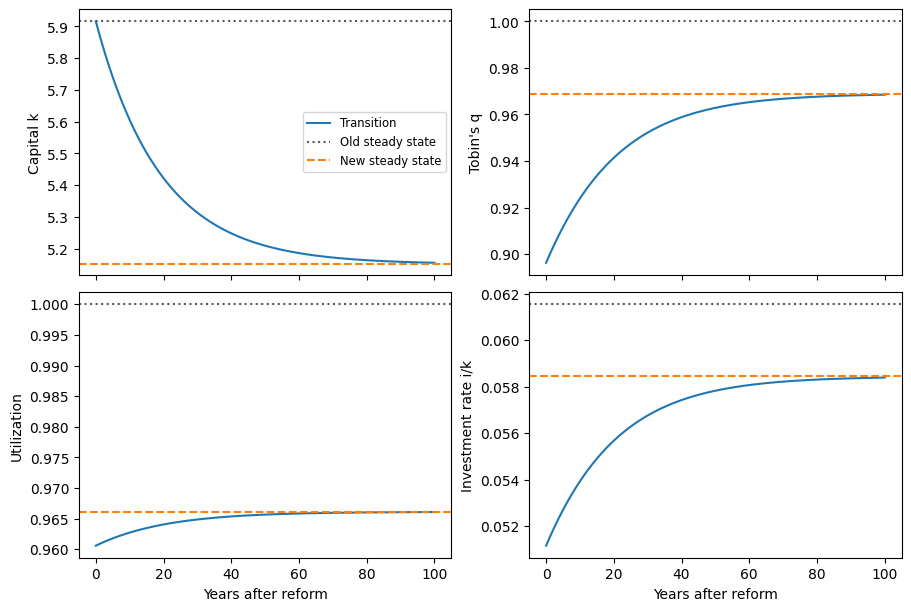

In [4]:
def kq_rhs(t, y, m):
    """Capital and q dynamics at the post-reform tax."""
    k, q = y
    investment_gap, q_dot = steady_residual((k, q), m.τ1, m)
    return np.array([k * investment_gap, q_dot])


def shoot_q(q0, m, ss=None):
    """Return the direction of the miss and the terminal-event IVP path."""
    k0 = old_capital(m)
    if ss is None:
        ss = steady_state(m.τ1, m, (k0, 1.0))
    target_k = ss[0]
    initial = (k0, q0)
    if kq_rhs(0, initial, m)[0] >= 0:
        return 1, None

    def cross_target(t, y):
        return y[0] - target_k

    def turn_up(t, y):
        return kq_rhs(t, y, m)[0]

    cross_target.terminal, cross_target.direction = True, -1
    turn_up.terminal, turn_up.direction = True, 1
    path = solve_ivp(
        lambda t, y: kq_rhs(t, y, m), (0.0, 1000.0), initial,
        events=(cross_target, turn_up), dense_output=True, rtol=1e-12, atol=1e-12,
    )
    if not path.success:
        raise RuntimeError(path.message)
    return (-1 if path.t_events[0].size else 1), path


def bisect_q0(m, ss=None):
    """Bracket and bisect the initial q, reusing the target steady state."""
    if ss is None:
        ss = steady_state(m.τ1, m, (old_capital(m), 1.0))
    low, high = 0.3, 1.0
    if shoot_q(low, m, ss)[0] != -1 or shoot_q(high, m, ss)[0] != 1:
        raise ValueError("The prescribed initial q bracket does not contain the saddle path.")
    while high - low >= 1e-13:
        mid = (low + high) / 2
        sign, _ = shoot_q(mid, m, ss)
        if sign == -1:
            low = mid
        else:
            high = mid
    q0 = (low + high) / 2
    _, path = shoot_q(q0, m, ss)
    return q0, path


q0, capital_path = bisect_q0(m1, ss_new)
u0 = utilization(q0, k_closed, m1.τ1, m1)
print(f"q(0) = {q0:.12f}, utilization(0) = {u0:.10f}, new steady utilization = {ss_new[2]:.10f}")
print(f"Bisected path exit time = {capital_path.t[-1]:.6f} years")

capital_times = np.linspace(0, 100, 401)
k_path, q_path = capital_path.sol(capital_times)
u_path, investment_path, _ = capital_terms(k_path, q_path, m1.τ1, m1)
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, layout="constrained")
panels = [
    ("Capital k", k_path, ss_old[0], ss_new[0]),
    ("Tobin's q", q_path, ss_old[1], ss_new[1]),
    ("Utilization", u_path, ss_old[2], ss_new[2]),
    ("Investment rate i/k", investment_path, depreciation(ss_old[2], m1), depreciation(ss_new[2], m1)),
]
for ax, (label, series, old, new) in zip(axes.flat, panels):
    ax.plot(capital_times, series, label="Transition")
    ax.axhline(old, linestyle=":", color="0.35", label="Old steady state")
    ax.axhline(new, linestyle="--", color="tab:orange", label="New steady state")
    ax.set_ylabel(label)
for ax in axes[-1]:
    ax.set_xlabel("Years after reform")
axes[0, 0].legend(fontsize="small")
plt.show()

**(c) Consumption by quadrature.** With $b(0)=0$ and $r=\rho$, integrating the budget constraint gives

$$
c=r\int_0^\infty e^{-rt}\,n(t)\,dt,\qquad n=w+(1-\tau_1)r^kmk+\tau_1\theta\bar\delta k+e-i-\Phi .
$$

Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">consumption(path, m)</code> returning $c$: $r$ times the integral, computed with the trapezoid rule (np.trapezoid, or np.trapz in NumPy older than 2.0) on 20001 equally spaced points up to the exit time $t_e$ of the bisected path of (b), and adding the new steady state after it, $e^{-rt_e}\,n^\star/r$. Solve the same problem with solve_bvp on $[0,T]$, $T=200$, for $(k,q,b)$ with $c$ as an unknown parameter (<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">p=[c]</code>):

$$
\left\{\begin{array}{lll}
(\dot k,\dot q)\ \text{as in (b)} & & \text{saddle block}\\[3pt]
\dot b(t)=rb+n(t)-c & & \text{current account, }c\text{ unknown}\\[6pt]
k(0)=k^\star(\tau_0) & t=0 & \text{initial, old steady state}\\[3pt]
b(0)=0 & t=0 & \text{initial}\\[3pt]
k(T)=k^\star(\tau_1) & t=T & \text{terminal, new steady state}\\[3pt]
rb(T)+n(T)-c=0 & t=T & \text{terminal, }\dot b(T)=0
\end{array}\right.
$$

on an initial mesh of 401 points, with the initial guess $k$ linear between the steady states, $q=q^\star(\tau_1)$, $b=0$, $c=1$ (<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">p=[1.0]</code>), <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">tol=1e-10</code> and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">max&#95;nodes=200&#95;000</code>. Then:

(i) Report $c$ from the quadrature and from solve_bvp, $|c_{\rm quad}-c_{\rm bvp}|$ and $|q_{\rm shoot}(0)-q_{\rm bvp}(0)|$.

(ii) Integrate $\dot b=rb+n(t)-c$ forward from $b(0)=0$ with solve_ivp, with $c$ from the quadrature and $n(t)$ along the path of (b), and plot $b(t)$ on $[0,100]$.

Consumption by quadrature = 0.922695980200
Consumption by solve_bvp = 0.922695965833
Absolute consumption difference = 1.437e-08
Absolute initial-q difference = 1.813e-13
Boundary solver converged on 838 mesh nodes
Foreign assets at year 100 = 0.97320301


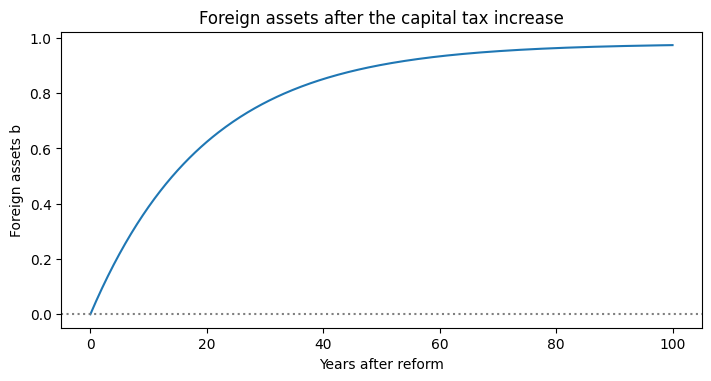

In [5]:
def net_income(k, q, m):
    """Household income net of gross investment and adjustment costs."""
    u, investment_rate, rental_per_capital = capital_terms(k, q, m.τ1, m)
    wage = (1 - m.β) * m.A * (u * k)**m.β
    after_tax_rent = ((1 - m.τ1) * rental_per_capital + m.τ1 * m.θ * m.δ_bar) * k
    adjustment = m.η / 2 * (investment_rate - m.z)**2 * k
    return wage + after_tax_rent + m.e - investment_rate * k - adjustment


def discounted_annuity(path, rate, flow, steady_flow):
    """Annuity value from trapezoid quadrature and a constant steady-state tail."""
    exit_time = path.t[-1]
    grid = np.linspace(0, exit_time, 20_001)
    k, q = path.sol(grid)
    discount = np.exp(-rate * grid)
    trapezoid = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    return rate * trapezoid(discount * flow(k, q), grid) + discount[-1] * steady_flow


def consumption(path, m):
    """Constant consumption implied by the present-value budget constraint."""
    target = steady_state(m.τ1, m, tuple(path.y[:, -1]))
    return discounted_annuity(
        path, m.r, lambda k, q: net_income(k, q, m), net_income(*target[:2], m)
    )


def solve_tax_bvp(m, old, new):
    """Solve the joint transition with consumption as an unknown parameter."""
    def rhs(t, y, p):
        k, q, b = y
        return np.vstack((kq_rhs(t, (k, q), m), m.r * b + net_income(k, q, m) - p[0]))

    def boundary(left, right, p):
        k_end, q_end, b_end = right
        return np.array([
            left[0] - old[0], left[2], k_end - new[0],
            m.r * b_end + net_income(k_end, q_end, m) - p[0],
        ])

    mesh = np.linspace(0, 200, 401)
    guess = np.vstack((
        np.linspace(old[0], new[0], mesh.size),
        np.full(mesh.size, new[1]),
        np.zeros(mesh.size),
    ))
    result = solve_bvp(rhs, boundary, mesh, guess, p=[1.0], tol=1e-10, max_nodes=200_000)
    if not result.success:
        raise RuntimeError(result.message)
    return result


c_quad = consumption(capital_path, m1)
bvp = solve_tax_bvp(m1, ss_old, ss_new)
print(f"Consumption by quadrature = {c_quad:.12f}")
print(f"Consumption by solve_bvp = {bvp.p[0]:.12f}")
print(f"Absolute consumption difference = {abs(c_quad - bvp.p[0]):.3e}")
print(f"Absolute initial-q difference = {abs(q0 - bvp.y[1, 0]):.3e}")
print(f"Boundary solver converged on {bvp.x.size:,} mesh nodes")


def current_account(t, b):
    return m1.r * b + net_income(*capital_path.sol(t), m1) - c_quad


bond_path = solve_ivp(
    current_account, (0, 100), [0.0], t_eval=capital_times, rtol=1e-10, atol=1e-12
)
if not bond_path.success:
    raise RuntimeError(bond_path.message)
print(f"Foreign assets at year 100 = {bond_path.y[0, -1]:.8f}")

fig, ax = plt.subplots(figsize=(7, 3.7), layout="constrained")
ax.plot(bond_path.t, bond_path.y[0])
ax.axhline(0, linestyle=":", color="0.5")
ax.set(xlabel="Years after reform", ylabel="Foreign assets b", title="Foreign assets after the capital tax increase")
plt.show()

**(d) The dynamic Laffer curve.** For $\tau_1\in\{0.30,0.35,\dots,0.90\}$ (use <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">m1._replace(τ1=...)</code> and the steady states of (a); at $\tau_1=\tau_0$ there is no transition and $PV=R(\tau_0)/r$), repeat the shooting of (b) and compute the present value of revenue along the transition,

$$
PV(\tau_1)=\int_0^\infty e^{-rt}\,\tau_1\big(r^k_tm_t-\theta\bar\delta\big)k_t\,dt ,
$$

with the trapezoid rule up to $t_e$ plus the tail $e^{-rt_e}R(\tau_1)/r$, as in (c). Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">dynamic&#95;revenue(tau1, m)</code> returning the annuity value $r\,PV(\tau_1)$. The loop over $\tau_1$ takes about 10 seconds. Then:

Plot the annuity value $r\,PV(\tau_1)$ together with $R(\tau_1)$ from (a), and report the revenue-maximizing tax of each curve.

Static maximum = 0.31383659 at tax 70%
Dynamic annuity maximum = 0.36098618 at tax 80%
Annuity at the 40% reform = 0.23104803
Revenue annuity gain versus the 30% baseline = 0.05162612


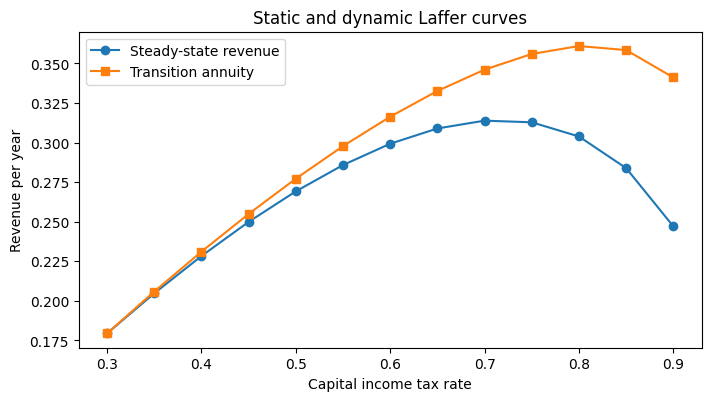

In [6]:
def dynamic_revenue(tau1, m):
    """Return the annuity value of capital tax revenue after a permanent reform."""
    tau1 = float(tau1)
    if tau1 == m.τ0:
        return tax_revenue(old_capital(m), 1.0, tau1, m)
    reform = m._replace(τ1=tau1)
    target = steady_states.get(tau1) if reform._replace(τ1=m1.τ1) == m1 else None
    if target is None:
        target = steady_state(tau1, reform, (old_capital(m), 1.0))
    _, path = bisect_q0(reform, target)
    return discounted_annuity(
        path, m.r, lambda k, q: tax_revenue(k, q, tau1, reform),
        tax_revenue(*target[:2], tau1, reform),
    )


dynamic_revenues = np.array([dynamic_revenue(tau, m1) for tau in tax_grid])
dynamic_best = tax_grid[dynamic_revenues.argmax()]
print(f"Static maximum = {static_revenues.max():.8f} at tax {static_best:.0%}")
print(f"Dynamic annuity maximum = {dynamic_revenues.max():.8f} at tax {dynamic_best:.0%}")
baseline_index = np.flatnonzero(tax_grid == m1.τ0)[0]
reform_index = np.flatnonzero(tax_grid == m1.τ1)[0]
print(f"Annuity at the 40% reform = {dynamic_revenues[reform_index]:.8f}")
print(f"Revenue annuity gain versus the 30% baseline = {dynamic_revenues[reform_index] - static_revenues[baseline_index]:.8f}")

fig, ax = plt.subplots(figsize=(7, 3.9), layout="constrained")
ax.plot(tax_grid, static_revenues, "o-", label="Steady-state revenue")
ax.plot(tax_grid, dynamic_revenues, "s-", label="Transition annuity")
ax.set(xlabel="Capital income tax rate", ylabel="Revenue per year", title="Static and dynamic Laffer curves")
ax.legend()
plt.show()

# Question 2. Dynamic Portfolio choice (30 points)

In this exercise you solve a portfolio problem with time-varying expected returns. You compute a finite-difference solution by policy iteration, solve the same problem with a critic and an actor network (deep policy iteration), and compare the two.

Expected stock returns move over time. How much stock does a long-horizon investor hold, and can a network learn the answer? The problem has one state variable, so a finite-difference solution is cheap and serves as the benchmark.

**Model.**

*Market.* A riskless bond pays $r$. The Sharpe ratio $X$ of a stock mean-reverts, and its shocks are correlated with returns:

$$
\frac{dS}{S}=(r+\sigma X)\,dt+\sigma\,dZ_1,\qquad dX=\kappa(\bar X-X)\,dt+\sigma_X\,dZ_2,\qquad dZ_1\,dZ_2=\varrho\,dt .
$$

*Investor.* CRRA utility over consumption $C$; she holds a share $\alpha$ of wealth $W$ in the stock:

$$
\max_{C,\alpha}\ \mathbb E\int_0^\infty e^{-\rho t}\,\frac{C_t^{1-\gamma}}{1-\gamma}\,dt\qquad\text{s.t.}\qquad dW=\big[(r+\alpha\sigma X)W-C\big]dt+\alpha W\sigma\,dZ_1 .
$$

*HJB.* The state is $(W,X)$. By Itô's lemma, with $\mathrm{cov}(dW,dX)=\alpha W\sigma\sigma_X\varrho\,dt$,

$$
\rho V=\max_{C,\alpha}\Big\{\frac{C^{1-\gamma}}{1-\gamma}+V_W\big[(r+\alpha\sigma X)W-C\big]+\tfrac12V_{WW}\alpha^2\sigma^2W^2+V_{WX}\,\alpha W\sigma\sigma_X\varrho\Big\}+V_X\,\kappa(\bar X-X)+\tfrac12V_{XX}\,\sigma_X^2 .
$$

*Homogeneity.* Guess $V=\phi(X)\,W^{1-\gamma}/(1-\gamma)$ and write $C=cW$. Dividing by $W^{1-\gamma}$ gives an equation in $X$ alone:

$$
0=\max_{c,\alpha}\Big\{\frac{c^{1-\gamma}}{1-\gamma}+\phi\Big(r+\alpha\sigma X-c-\frac\gamma2\alpha^2\sigma^2\Big)+\alpha\varrho\sigma\sigma_X\phi'\Big\}+\frac{\kappa(\bar X-X)\phi'+\frac12\sigma_X^2\phi''-\rho\phi}{1-\gamma}.
$$

*FOCs.* The risky share is a myopic demand plus a hedging demand that appears only when returns and $X$ are correlated:

$$
c=\phi^{-1/\gamma},\qquad \alpha=\underbrace{\frac{X}{\gamma\sigma}}_{\text{myopic}}+\underbrace{\frac{\varrho\,\sigma_X}{\gamma\,\sigma}\,\frac{\phi'(X)}{\phi(X)}}_{\text{hedging}} .
$$
*Fixed policies.* For given $(c,\alpha)$ the max drops, and multiplying by $1-\gamma$ turns the HJB into a linear ODE in $\phi$:

$$
\Big[\rho-(1-\gamma)\Big(r+\alpha\sigma X-c-\frac\gamma2\alpha^2\sigma^2\Big)\Big]\phi-\mu_\phi\,\phi'-\tfrac12\sigma_X^2\,\phi''=c^{1-\gamma},\qquad \mu_\phi=\kappa(\bar X-X)+(1-\gamma)\,\alpha\varrho\sigma\sigma_X .
$$

Solving the HJB alternates between this ODE (for $\phi$ given the policies) and the FOCs (for the policies given $\phi$).

**Numerical methods.** Methods 2 and 3 are both policy iteration: *evaluate* fixed policies $(c,\alpha)$, then *improve* them with the FOCs. They differ in how $\phi$ is represented.

1. Closed forms, part (a): the myopic share ($\varrho=0$) and log utility ($\gamma\to1$), used as benchmarks.
2. Finite differences, part (b), the benchmark (Lecture 11). Evaluation solves the linear ODE above: on the grid, with an upwind difference for $\phi'$, a central difference for $\phi''$ and reflecting edges, it is one sparse tridiagonal solve, with $B(c,\alpha)$ the discretized left-hand side of the ODE. Improvement applies the FOCs:
   $$
   B(c^n,\alpha^n)\,\phi^{n+1}=(c^n)^{1-\gamma},\qquad (c^{n+1},\alpha^{n+1})=\Big(\big(\phi^{n+1}\big)^{-1/\gamma},\ \frac{X}{\gamma\sigma}+\frac{\varrho\,\sigma_X}{\gamma\,\sigma}\frac{(\phi^{n+1})'}{\phi^{n+1}}\Big).
   $$
3. Deep policy iteration, parts (c) and (d) (Lecture 12). A critic network represents $\phi$ and an actor network represents $(\ln c,\alpha)$. There is no grid: $\phi'$ and $\phi''$ come from automatic differentiation. The HJB residual is the right-hand side of the HJB in $X$, evaluated at the networks and without the max,
   $$
   \begin{aligned}
   \mathcal R(X)&=\frac{c^{1-\gamma}}{1-\gamma}+\phi\Big(r+\alpha\sigma X-c-\frac\gamma2\alpha^2\sigma^2\Big)+\alpha\varrho\sigma\sigma_X\phi'+\frac{\kappa(\bar X-X)\phi'+\frac12\sigma_X^2\phi''-\rho\phi}{1-\gamma},\\[4pt]
   &\phi=\phi_\theta(X),\qquad (c,\alpha)=\big(c_\vartheta(X),\alpha_\vartheta(X)\big),
   \end{aligned}
   $$
   so that the HJB reads $\max_{c,\alpha}\mathcal R(X)=0$. It is evaluated at random points $X_b$. Each iteration takes one gradient step per network: the critic sets $\mathcal R$ to zero at the current policies, and the actor maximizes $\mathcal R$ at the current $\phi$ (whose first-order conditions are the FOCs above):
   $$
   \text{critic (evaluation):}\ \ \min_\theta\ \frac1B\sum_b\Big(\frac{\mathcal R(X_b)}{\phi_\theta(X_b)}\Big)^2,\qquad \text{actor (improvement):}\ \ \max_\vartheta\ \frac1B\sum_b\frac{\mathcal R(X_b)}{\phi_\theta(X_b)} .
   $$
   The finite-difference solution of method 2 measures the error of the networks.

**Parameters.** $r=0.02$, $\sigma=0.15$, $\kappa=0.27$, $\bar X=0.35$, $\sigma_X=0.065$, $\varrho=-0.9$, $\gamma=4$, $\rho=0.04$. The stationary standard deviation of $X$ is $s_X=\sigma_X/\sqrt{2\kappa}\approx0.088$. The finite-difference grid covers $\bar X\pm6s_X$ with $401$ points, so that its reflecting edges do not affect the solution where we look at it; report all results on $\bar X\pm3s_X$. In the code the correlation $\varrho$ is called <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">corr</code> (Python reads <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">ϱ</code> and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">ρ</code> as the same name).

In [7]:
import torch
import torch.nn as nn


class Portfolio(NamedTuple):
    r: float          # riskless rate
    σ: float          # stock volatility
    κ: float          # mean reversion of X
    X_bar: float      # mean Sharpe ratio
    σ_X: float        # volatility of X
    corr: float       # correlation of dZ1 and dZ2 (ϱ)
    γ: float          # risk aversion
    ρ: float          # discount rate
    s_X: float        # stationary sd of X
    X: np.ndarray     # FD grid on X_bar ± width s_X
    dX: float


def create_portfolio(r=0.02, σ=0.15, κ=0.27, X_bar=0.35, σ_X=0.065, corr=-0.9, γ=4.0, ρ=0.04,
                     N=401, width=6.0):
    s_X = σ_X / np.sqrt(2*κ)
    X, dX = np.linspace(X_bar - width*s_X, X_bar + width*s_X, N, retstep=True)
    return Portfolio(r, σ, κ, X_bar, σ_X, corr, γ, ρ, s_X, X, dX)


def make_net(n_in=1, n_out=1, width=32, depth=2):
    "A fully connected network with tanh activations."
    layers, n = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(n, width), nn.Tanh()]
        n = width
    layers += [nn.Linear(n, n_out)]
    return nn.Sequential(*layers)


m3 = create_portfolio()
print(f"s_X = {m3.s_X:.4f},  FD grid [{m3.X[0]:.3f}, {m3.X[-1]:.3f}],  report on [{m3.X_bar - 3*m3.s_X:.3f}, {m3.X_bar + 3*m3.s_X:.3f}]")

s_X = 0.0885,  FD grid [-0.181, 0.881],  report on [0.085, 0.615]


**(a) Myopic benchmark.** With $\varrho=0$ the risky share is myopic, $\alpha=X/(\gamma\sigma)$; with log utility ($\gamma\to1$), $c=\rho$ and $\alpha=X/\sigma$.

Plot both shares on $\bar X\pm3s_X$.

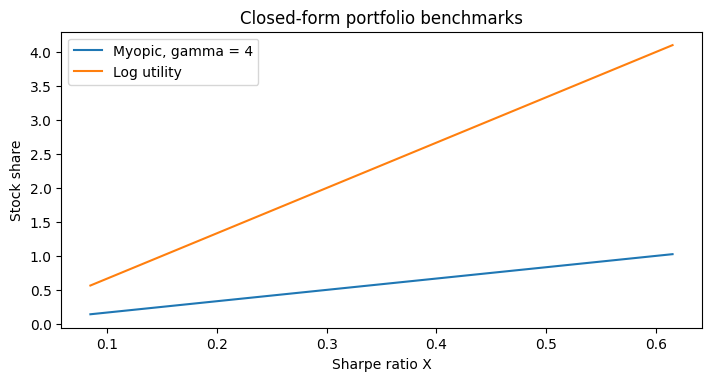

In [8]:
def report_window(m):
    xi = (m.X - m.X_bar) / m.s_X
    return np.abs(xi) <= 3 + 1e-12


X_plot = m3.X[report_window(m3)]
fig, ax = plt.subplots(figsize=(7, 3.7), layout="constrained")
ax.plot(X_plot, X_plot / (m3.γ * m3.σ), label=f"Myopic, gamma = {m3.γ:g}")
ax.plot(X_plot, X_plot / m3.σ, label="Log utility")
ax.set(xlabel="Sharpe ratio X", ylabel="Stock share", title="Closed-form portfolio benchmarks")
ax.legend()
plt.show()

**(b) Finite differences by policy iteration.** Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">evaluate(c, alpha, m)</code> returning $\phi$ on the grid, the solution of the linear ODE for fixed policies: upwind $\phi'$ (forward difference where $\mu_\phi>0$, backward where $\mu_\phi<0$), central differences for $\phi''$, reflecting edges ($\phi_{-1}=\phi_0$, $\phi_N=\phi_{N-1}$), and a sparse tridiagonal solve with spsolve.

 Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">improve(phi, m)</code> returning $(c,\alpha)$ from the FOCs (np.gradient for $\phi'$). Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">solve&#95;pi(m)</code> that evaluates at $c=\rho$, $\alpha=X/(\gamma\sigma)$, then alternates improvement and evaluation until $\max|\phi^{n+1}/\phi^n-1|<10^{-10}$ (a relative criterion: $\phi$ is of order $\rho^{-\gamma}\approx4\times10^5$), and returns $\phi$, $c$, $\alpha$, the hedging demand $\alpha-X/(\gamma\sigma)$ and the number of improvement steps. Then:

(i) Report the number of improvement steps and the run time, and plot $c$, $\alpha$ and the hedging demand on $\bar X\pm3s_X$.

(ii) Solve with $\gamma=1.0001$ (use <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">m3.&#95;replace(γ=1.0001)</code>) and report the largest differences of $c$ and $\alpha$ from the log-utility values $c=\rho$, $\alpha=X/\sigma$ of (a), on $\bar X\pm3s_X$.

(iii) Solve on grids covering $\bar X\pm8s_X$ and $\bar X\pm3s_X$ with about the same grid step (<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create&#95;portfolio(width=8.0, N=535)</code> and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create&#95;portfolio(width=3.0, N=201)</code>), and report for each the largest change in $\alpha$ at its nodes in $\bar X\pm3s_X$ relative to the baseline solution, interpolated to those nodes with np.interp.

Policy improvement steps = 4, run time = 0.0024 s


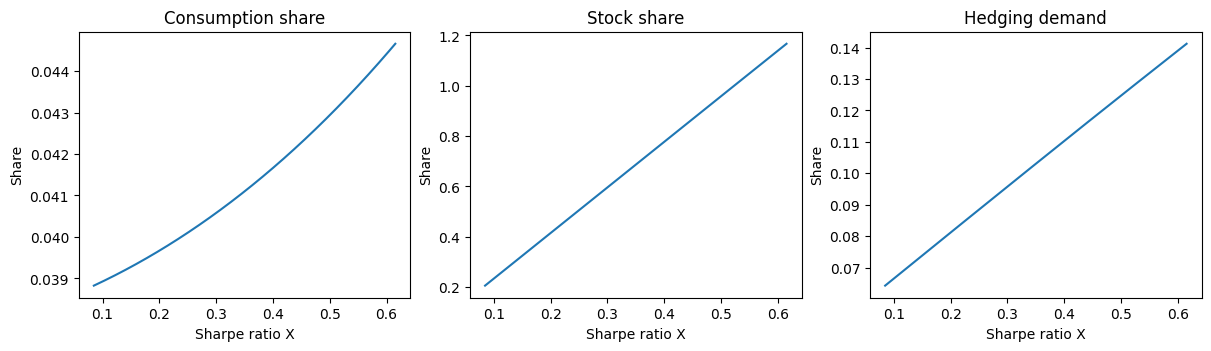

Near-log maximum consumption error = 5.934840e-06
Near-log maximum stock-share error = 3.482746e-04
Half-width 8 s_X maximum stock-share change = 1.245502e-05
Half-width 3 s_X maximum stock-share change = 1.333307e-01


In [9]:
def evaluate(c, alpha, m):
    """Evaluate fixed policies with a sparse tridiagonal finite-difference solve."""
    growth = m.r + alpha * m.σ * m.X - c - m.γ / 2 * (alpha * m.σ)**2
    reaction = m.ρ - (1 - m.γ) * growth
    drift = m.κ * (m.X_bar - m.X) + (1 - m.γ) * alpha * m.corr * m.σ * m.σ_X
    diffusion = 0.5 * (m.σ_X / m.dX)**2
    lower_weight = diffusion + np.maximum(-drift, 0) / m.dX
    upper_weight = diffusion + np.maximum(drift, 0) / m.dX
    diagonal = reaction + lower_weight + upper_weight

    # A reflecting ghost value equals the adjacent endpoint value.
    diagonal[0] -= lower_weight[0]
    diagonal[-1] -= upper_weight[-1]
    matrix = sparse.diags(
        (-lower_weight[1:], diagonal, -upper_weight[:-1]), (-1, 0, 1), format="csc"
    )
    return spsolve(matrix, c**(1 - m.γ))


def improve(phi, m):
    """Update consumption and the stock share using the two first-order conditions."""
    if np.any(phi <= 0) or not np.all(np.isfinite(phi)):
        raise ValueError("Policy improvement requires a finite positive value coefficient.")
    c = phi**(-1 / m.γ)
    slope = np.gradient(phi, m.dX)
    myopic = m.X / (m.γ * m.σ)
    alpha = myopic + (m.corr * m.σ_X / (m.γ * m.σ)) * slope / phi
    return c, alpha


def solve_pi(m):
    """Alternate policy evaluation and improvement until the value stabilizes."""
    myopic = m.X / (m.γ * m.σ)
    phi = evaluate(np.full_like(m.X, m.ρ), myopic, m)
    for step in range(1, 201):
        c, alpha = improve(phi, m)
        updated_phi = evaluate(c, alpha, m)
        if np.max(np.abs(updated_phi / phi - 1)) < 1e-10:
            c, alpha = improve(updated_phi, m)
            return updated_phi, c, alpha, alpha - myopic, step
        phi = updated_phi
    raise RuntimeError("Finite-difference policy iteration did not converge.")


start = time.perf_counter()
phi_fd, c_fd, alpha_fd, hedge_fd, pi_steps = solve_pi(m3)
print(f"Policy improvement steps = {pi_steps}, run time = {time.perf_counter() - start:.4f} s")
mask = report_window(m3)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True, layout="constrained")
for ax, series, title in zip(axes, (c_fd, alpha_fd, hedge_fd), ("Consumption share", "Stock share", "Hedging demand")):
    ax.plot(m3.X[mask], series[mask])
    ax.set(xlabel="Sharpe ratio X", ylabel="Share", title=title)
plt.show()

near_log = m3._replace(γ=1.0001)
_, c_log, alpha_log, _, _ = solve_pi(near_log)
print(f"Near-log maximum consumption error = {np.max(np.abs(c_log[mask] - near_log.ρ)):.6e}")
print(f"Near-log maximum stock-share error = {np.max(np.abs(alpha_log[mask] - m3.X[mask] / m3.σ)):.6e}")
for width, size in ((8.0, 535), (3.0, 201)):
    model = create_portfolio(width=width, N=size)
    _, _, alternative, _, _ = solve_pi(model)
    keep = report_window(model)
    baseline = np.interp(model.X[keep], m3.X, alpha_fd)
    print(f"Half-width {width:g} s_X maximum stock-share change = {np.max(np.abs(alternative[keep] - baseline)):.6e}")

**(c) Critic and actor networks.** Use two networks, a critic for the value and an actor for the policies, with the standardized input $\xi=(X-\bar X)/s_X$:

$$
\phi_\theta(X)=\rho^{-\gamma}\exp\big(\mathrm{NN}_\theta(\xi)\big),\qquad \big(\ln c,\ \alpha\big)=\big(\ln\rho,\ 0\big)+\mathrm{NN}_\vartheta(\xi),
$$

with <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">NN = make_net()</code> for the critic and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">make_net(n_out=2)</code> for the actor (the factors $\rho^{-\gamma}$ and $\ln\rho$ start both networks near the log-utility solution). Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">hjb_residual(X, critic, actor, m)</code> returning $\mathcal R(X)$, the right-hand side of the HJB in $X$ alone evaluated at the actor's $(c,\alpha)$, without the max, with $\phi'$ and $\phi''$ by automatic differentiation (torch.autograd.grad with <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create_graph=True</code>). Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">train(m, wide=4.0)</code> returning the two trained networks and the run time, where wide is the sampling half-width in units of $s_X$ (an argument, since (d) changes it). Set torch.manual_seed(0) at the start of each training. Each iteration draw $B=256$ points $X_b$ uniformly on $\bar X\pm4s_X$ and take one Adam step on the actor, then one on the critic (recompute $\mathcal R$ after the actor step):

$$
\vartheta\leftarrow\vartheta+\eta_a\nabla_\vartheta\frac1B\sum_b\frac{\mathcal R(X_b)}{\phi_\theta(X_b)}\quad\text{(the actor maximizes the HJB, }\phi_\theta\text{ held fixed)},\qquad \theta\leftarrow\theta-\eta_c\nabla_\theta\frac1B\sum_b\Big(\frac{\mathcal R(X_b)}{\phi_\theta(X_b)}\Big)^2\quad\text{(the critic sets it to zero, policies held fixed)}.
$$

Use learning rates $\eta_a=\eta_c=10^{-3}$, decaying exponentially to $0.05$ times their initial value at the end of the run (torch.optim.lr_scheduler.ExponentialLR with gamma $=0.05^{1/5000}$, stepped once per iteration). Train 5000 iterations (under a minute). Then:

(i) Report, on the FD grid points in $\bar X\pm3s_X$, the max relative error in $\phi$, the max errors in $c$ and $\alpha$ against (b), the $\log_{10}$ RMSE of $\mathcal R/\phi$, and the run time.

(ii) Report the largest hedging demand from (b) on $\bar X\pm3s_X$ next to the max error in $\alpha$.

In [10]:
def critic_value(X, critic, m):
    xi = ((X - m.X_bar) / m.s_X).reshape(-1, 1)
    return (m.ρ**(-m.γ) * critic(xi).exp()).reshape(X.shape)


def actor_policies(X, actor, m):
    xi = ((X - m.X_bar) / m.s_X).reshape(-1, 1)
    log_c_offset, alpha = actor(xi).unbind(dim=1)
    return (m.ρ * log_c_offset.exp()).reshape(X.shape), alpha.reshape(X.shape)


def network_hjb(X, critic, actor, m, fixed=None):
    """Return the HJB residual and its positive normalizer at each point."""
    X = X.detach().clone().requires_grad_(True)
    phi = critic_value(X, critic, m)
    phi_x = torch.autograd.grad(phi.sum(), X, create_graph=True)[0]
    phi_xx = torch.autograd.grad(phi_x.sum(), X, create_graph=True)[0]
    X = X.detach()
    if fixed == "critic":
        phi, phi_x, phi_xx = phi.detach(), phi_x.detach(), phi_xx.detach()
    if fixed == "actor":
        with torch.no_grad():
            c, alpha = actor_policies(X, actor, m)
    else:
        c, alpha = actor_policies(X, actor, m)

    wealth_term = m.r + alpha * m.σ * X - c - m.γ / 2 * (alpha * m.σ).square()
    state_term = m.κ * (m.X_bar - X) * phi_x + 0.5 * m.σ_X**2 * phi_xx - m.ρ * phi
    residual = (
        c.pow(1 - m.γ) / (1 - m.γ) + phi * wealth_term
        + alpha * m.corr * m.σ * m.σ_X * phi_x
        + state_term / (1 - m.γ)
    )
    return residual, phi


def hjb_residual(X, critic, actor, m):
    """Return the unnormalized HJB residual evaluated under the actor policy."""
    return network_hjb(X, critic, actor, m)[0]


def train(m, wide=4.0):
    """Perform 5,000 alternating actor and critic updates on uniform batches."""
    torch.manual_seed(0)
    critic, actor = make_net(), make_net(n_out=2)
    actor_opt = torch.optim.Adam(actor.parameters(), lr=1e-3)
    critic_opt = torch.optim.Adam(critic.parameters(), lr=1e-3)
    steps, batch_size = 5000, 256
    decay = 0.05**(1 / steps)
    actor_schedule = torch.optim.lr_scheduler.ExponentialLR(actor_opt, gamma=decay)
    critic_schedule = torch.optim.lr_scheduler.ExponentialLR(critic_opt, gamma=decay)
    start = time.perf_counter()
    for _ in range(steps):
        X = m.X_bar + m.s_X * wide * (2 * torch.rand(batch_size) - 1)

        actor_opt.zero_grad(set_to_none=True)
        residual, phi = network_hjb(X, critic, actor, m, fixed="critic")
        actor_loss = -(residual / phi).mean()
        actor_loss.backward()
        actor_opt.step()

        critic_opt.zero_grad(set_to_none=True)
        residual, phi = network_hjb(X, critic, actor, m, fixed="actor")
        critic_loss = (residual / phi).square().mean()
        critic_loss.backward()
        critic_opt.step()

        actor_schedule.step()
        critic_schedule.step()
    return critic, actor, time.perf_counter() - start


def predict_policies(X, actor, m):
    """Evaluate the trained consumption and stock-share policies on NumPy inputs."""
    parameter = next(actor.parameters())
    with torch.no_grad():
        c, alpha = actor_policies(torch.as_tensor(X, dtype=parameter.dtype), actor, m)
    return c.numpy(), alpha.numpy()


# Small CPU batches are faster with one PyTorch thread.
torch.set_num_threads(1)
critic_nn, actor_nn, train_seconds = train(m3)
X_tensor = torch.as_tensor(m3.X[mask], dtype=next(critic_nn.parameters()).dtype)
nn_residual, phi_nn = network_hjb(X_tensor, critic_nn, actor_nn, m3)
c_nn, alpha_nn = predict_policies(m3.X[mask], actor_nn, m3)
phi_error = np.max(np.abs(phi_nn.detach().numpy() / phi_fd[mask] - 1))
c_error = np.max(np.abs(c_nn - c_fd[mask]))
alpha_error = np.max(np.abs(alpha_nn - alpha_fd[mask]))
log_rmse = torch.log10((nn_residual / phi_nn).square().mean().sqrt()).item()
print(f"Maximum relative value error = {phi_error:.6e}")
print(f"Maximum absolute consumption-share error = {c_error:.6e}")
print(f"Maximum absolute stock-share error = {alpha_error:.6e}")
print(f"log10 RMSE of normalized HJB residual = {log_rmse:.6f}, training = {train_seconds:.2f} s")
print(f"Largest absolute finite-difference hedge = {np.max(np.abs(hedge_fd[mask])):.6e}, stock-share error = {alpha_error:.6e}")

Maximum relative value error = 6.600368e-04
Maximum absolute consumption-share error = 2.309515e-05
Maximum absolute stock-share error = 4.204151e-03
log10 RMSE of normalized HJB residual = -4.269486, training = 8.71 s
Largest absolute finite-difference hedge = 1.411935e-01, stock-share error = 4.204151e-03


**(d) Hedging demand.** With the methods of (b) and (c):

(i) For $\varrho\in\{-0.9,0,0.9\}$ and $\gamma\in\{2,4\}$, plot the hedging demand from (b) and (c) on $\bar X\pm3s_X$; for (c) it is $\alpha_{\rm NN}-X/(\gamma\sigma)$ with $\alpha_{\rm NN}$ from the actor (six cases, five new trainings of about half a minute each).

(ii) For $\varrho=-0.9$, $\gamma=4$, plot $|\alpha_{\rm NN}-\alpha_{\rm FD}|$ against $X$ on $\bar X\pm3s_X$.

(iii) Retrain that case with $X_b$ drawn only on $\bar X\pm3s_X$ and add its error to the same plot.

gamma = 2, correlation = -0.9, training = 9.10 s


gamma = 2, correlation = +0.0, training = 9.17 s


gamma = 2, correlation = +0.9, training = 8.80 s


gamma = 4, correlation = +0.0, training = 9.14 s


gamma = 4, correlation = +0.9, training = 9.03 s


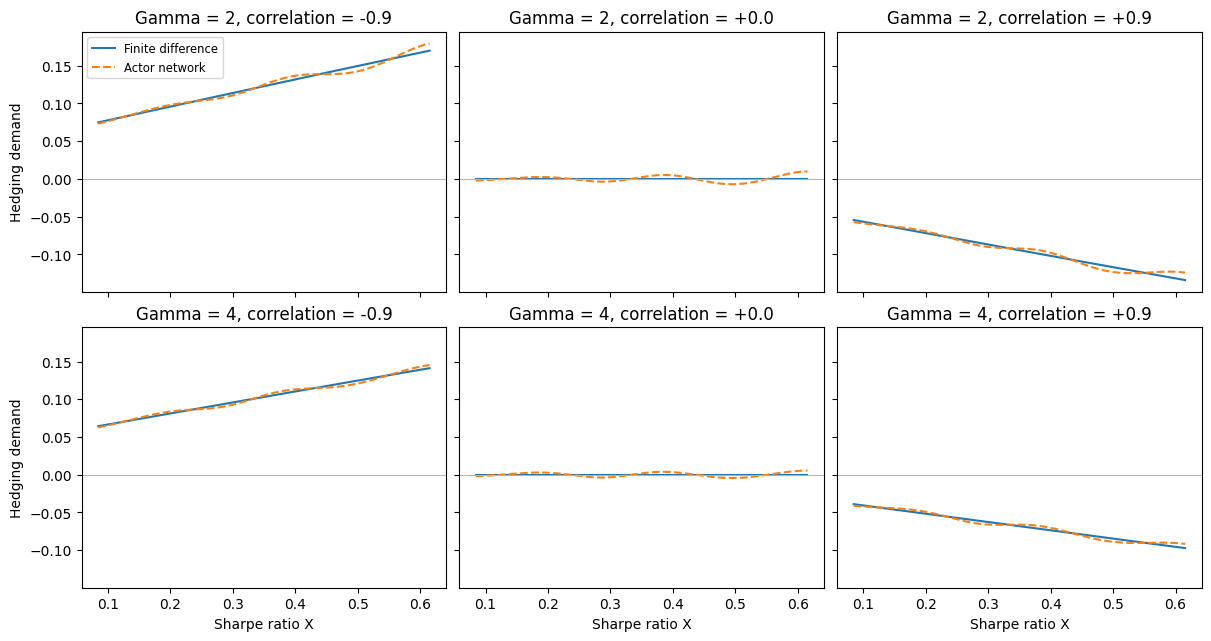

Training on ±3 s_X = 8.44 s, maximum stock-share error = 2.499099e-02


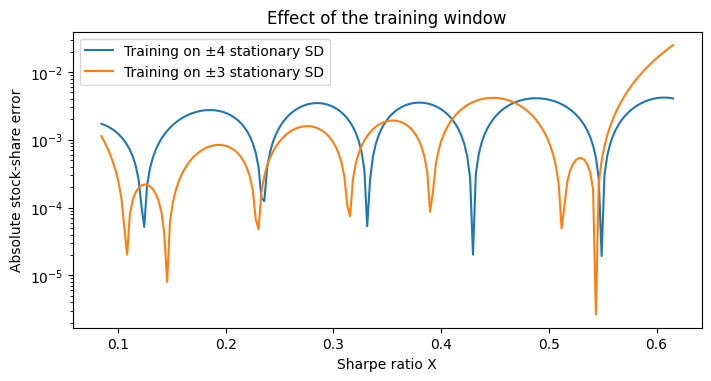

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.3), sharex=True, sharey=True, layout="constrained")
for row, gamma in enumerate((2.0, 4.0)):
    for column, corr in enumerate((-0.9, 0.0, 0.9)):
        model = m3._replace(γ=gamma, corr=corr)
        inside = report_window(model)
        X = model.X[inside]
        if gamma == m3.γ and corr == m3.corr:
            hedge = hedge_fd[inside]
            predicted_alpha = alpha_nn
        else:
            _, _, _, hedge_all, _ = solve_pi(model)
            hedge = hedge_all[inside]
            _, actor, elapsed = train(model)
            print(f"gamma = {gamma:g}, correlation = {corr:+.1f}, training = {elapsed:.2f} s")
            _, predicted_alpha = predict_policies(X, actor, model)
        network_hedge = predicted_alpha - X / (model.γ * model.σ)
        ax = axes[row, column]
        ax.plot(X, hedge, label="Finite difference")
        ax.plot(X, network_hedge, "--", label="Actor network")
        ax.axhline(0, color="0.7", linewidth=0.7)
        ax.set_title(f"Gamma = {gamma:g}, correlation = {corr:+.1f}")
for ax in axes[-1]:
    ax.set_xlabel("Sharpe ratio X")
for ax in axes[:, 0]:
    ax.set_ylabel("Hedging demand")
axes[0, 0].legend(fontsize="small")
plt.show()

_, actor_narrow, elapsed = train(m3, wide=3.0)
_, alpha_narrow = predict_policies(m3.X[mask], actor_narrow, m3)
error_wide = np.abs(alpha_nn - alpha_fd[mask])
error_narrow = np.abs(alpha_narrow - alpha_fd[mask])
print(f"Training on ±3 s_X = {elapsed:.2f} s, maximum stock-share error = {error_narrow.max():.6e}")
fig, ax = plt.subplots(figsize=(7, 3.7), layout="constrained")
ax.semilogy(m3.X[mask], error_wide, label="Training on ±4 stationary SD")
ax.semilogy(m3.X[mask], error_narrow, label="Training on ±3 stationary SD")
ax.set(xlabel="Sharpe ratio X", ylabel="Absolute stock-share error", title="Effect of the training window")
ax.legend()
plt.show()

# Question 3. Currency choice with menu costs (40 points)

In this exercise you solve a menu-cost model with a choice of currency on four state variables. You code the expectation along the axes of the value array, solve the model by value function iteration, find the firm that is indifferent between the two currencies, and simulate price changes and pass-through.

An exporter posts a price that stays fixed until it pays to change it. When it resets, it also chooses the currency of the price: the buyer's (local currency pricing, LCP) or its own (producer currency pricing, PCP). Which does it choose? This is the model of Gopinath, Itskhoki and Rigobon (2010).

**Model.**

*Demand.* The firm sells abroad. Its sales depend on its dollar price $p^{\rm usd}$ relative to the sector price $P$ (logs), with a demand elasticity that rises with the relative price (Kimball demand):

$$
q\big(p^{\rm usd}-P\big)=\Big(1-\varepsilon\,\big(p^{\rm usd}-P\big)\Big)^{\sigma/\varepsilon}.
$$

At $p^{\rm usd}=P$ the elasticity is $\sigma$; the desired markup falls with the relative price with elasticity $\Gamma=\varepsilon/(\sigma-1)$. With $\varepsilon=0$ demand is CES, $q=\exp\big(-\sigma(p^{\rm usd}-P)\big)$.

*Costs.* Marginal cost in dollars rises with the exchange rate $e$ (part of the inputs are priced in the firm's currency) and falls with productivity $a$:

$$
mc=\phi\,e-a .
$$

*Shocks.* Productivity and the exchange rate are independent AR(1) processes, discretized by Tauchen:

$$
a'=\rho_a\,a+\sigma_a\,\epsilon_a',\qquad e'=\rho_e\,e+\sigma_e\,\epsilon_e' .
$$

Competitors adjust gradually, so the sector price moves partly with the exchange rate:

$$
P'=g(P,e')=(1-\alpha)\bar P+\alpha P+(1-\alpha)\,\bar\phi\,e' .
$$

*Profits.* The posted price $p$ is quoted in a currency $c\in\{L,P\}$. The only thing that differs between the two regimes is what the number $p$ means, and so how the dollar price moves while the price is fixed:

$$
\text{LCP: } p^{\rm usd}=p,\qquad \text{PCP: } p^{\rm usd}=p+e .
$$

Everything else is the same in both regimes: demand $q(p^{\rm usd}-P)$, cost $mc=\phi e-a$, the shocks, $\delta$ and $\kappa$. That gives the two profit functions:

$$
\Pi_L(p,P,a,e)=\big(e^{p}-e^{\phi e-a}\big)\,q(p-P),\qquad \Pi_P(p,P,a,e)=\Pi_L(p+e,P,a,e).
$$
*State.* The firm's state has four continuous variables and one discrete one:

| State | Meaning | Type | Grid | Next period |
|:--|:--|:--|:--|:--|
| $p$ | posted price | endogenous | $N_p$ nodes | unchanged, unless reset |
| $P$ | sector price | exogenous | $N_P$ nodes | $g(P,e')$, on two neighbouring nodes |
| $a$ | productivity | exogenous | $N_a$ Tauchen nodes | $Q_a[a,a']$ |
| $e$ | exchange rate | exogenous | $N_e$ Tauchen nodes | $Q_e[e,e']$ |
| $c$ | currency of the price | contract | $\{L,P\}$ | unchanged, unless reset |

The value is stored as two arrays, one per currency, $H_c\in\mathbb R^{N_p\times N_P\times N_a\times N_e}$.

*Bellman equation.* With $z=(P,a,e)$ the exogenous state, $H_c(p,z)$ is the value of entering the period with price $p$ in currency $c$ after deciding to keep it:

$$
H_c(p,z)=\Pi_c(p,z)+\delta\,\mathbb E\Big[\max\Big\{\underbrace{H_c(p,z')}_{\text{keep}},\ \underbrace{\bar V(z')-\kappa}_{\text{reset}}\Big\}\ \Big|\ z\Big],\qquad \bar V(z)=\max_{c\in\{L,P\}}\ \max_{p}\ H_c(p,z).
$$

At a reset the firm chooses the currency and the price; the reset price is $p^*_c(z)=\arg\max_pH_c(p,z)$ and the currency is $c^*(z)=\arg\max_c\max_pH_c(p,z)$.

*Pass-through and the choice of currency.* The firm prefers LCP when the exchange rate moves its desired dollar price by less than one half over the life of a price. The value gap at the reference state $z_0$ (all shocks at their means, $P=\bar P$),

$$
\Delta V(\phi)=\max_pH_L(p,z_0)-\max_pH_P(p,z_0),
$$

is positive for low $\phi$ and negative for high $\phi$; the indifference value $\phi^*$ solves $\Delta V(\phi^*)=0$.

**Numerical methods.** This is a dynamic program with a discrete choice (keep or reset, and the currency) on a state with four continuous variables (Lecture 10). The value is an array with one axis per state variable, and the expectation is applied along the axes of the random states, never as one matrix on the whole state.

1. Expectation along axes, part (b). Write $U_c(p,z')=\max\{H_c(p,z'),\bar V(z')-\kappa\}$. Since $a'$ and $e'$ are independent and $P'$ is a known function of $(P,e')$, placed on the nodes $P_{k}$ and $P_{k+1}$ with weights $w$ and $1-w$ (so that $wP_k+(1-w)P_{k+1}=g(P,e')$), the expectation is three operations along axes:
   $$
   \begin{aligned}
   \mathbb E\,U(p,P,a,e)&=\sum_{e'}Q_e[e,e']\ \sum_{a'}Q_a[a,a']\Big[w\,U(p,P_k,a',e')+(1-w)\,U(p,P_{k+1},a',e')\Big],\\[4pt]
   &k=k(P,e'),\qquad w=w(P,e').
   \end{aligned}
   $$
   - Along $a$: <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">U = Qa @ U</code>, with $a$ as the second-to-last axis.
   - Along $P$: a gather with the index array $k(P,e')$ and the weights $w(P,e')$, both of shape $(N_P,N_e)$, giving $U(p,P_{k(P,e')},a,e')$. Use the node $\min(k+1,\,N_P-1)$ for $P_{k+1}$ (in the reduced model $N_P=1$ and $w=1$).
   - Along $e$: <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">EU = U @ Qe.T</code>.

   The gather must come before the sum over $e'$, because $P'$ depends on $e'$. A single transition matrix on the whole exogenous state would have $(N_PN_aN_e)^2$ entries.
2. Value function iteration, part (c). The Bellman operator $T$ maps a pair of arrays $H=(H_L,H_P)$ into $TH=\big((TH)_L,(TH)_P\big)$:
   $$
   \begin{aligned}
   (TH)_c(p,z)&=\Pi_c(p,z)+\delta\,\mathbb E\Big[\max\big\{H_c(p,z'),\ \bar V(z')-\kappa\big\}\ \Big|\ z\Big],\qquad c\in\{L,P\},\\[4pt]
   &\bar V(z)=\max_{c\in\{L,P\}}\max_pH_c(p,z),
   \end{aligned}
   $$
   with the expectation computed as in method 1. VFI iterates $H\leftarrow TH$ from $H=0$. With a monthly $\delta\approx0.9966$ the step $\|TH-H\|_\infty$ shrinks by only $0.34\%$ per iteration, so the usual rule $\|TH-H\|_\infty<\mathrm{tol}$ needs about $\ln(10^{-6})/\ln\delta\approx4000$ iterations. Instead, with $\underline d=\min(TH-H)$ and $\bar d=\max(TH-H)$, the solution $H^*$ is bracketed by the MacQueen-Porteus bounds
   $$
   TH+\frac{\delta}{1-\delta}\,\underline d\ \le\ H^*\ \le\ TH+\frac{\delta}{1-\delta}\,\bar d ,
   $$
   which tighten long before the step itself is small. Stop when the bracket is narrower than tol, and take its midpoint:
   $$
   \frac{\delta}{1-\delta}\,(\bar d-\underline d)<\mathrm{tol},\qquad H\leftarrow TH+\frac{\delta}{1-\delta}\,\frac{\bar d+\underline d}{2}.
   $$
3. Root finding, part (d). The indifference value $\phi^*$ solves $\Delta V(\phi^*)=0$ with brentq; each evaluation of $\Delta V$ is one solve of the reduced model.
4. Simulation, parts (e) and (f). A panel of firms is simulated with the policies, vectorized across firms, drawing $a'$ and $e'$ for each firm, independently across firms, from the rows of $Q_a$ and $Q_e$ by the inverse CDF. Pass-through is the slope of an OLS regression on the simulated price changes.

**Parameters** (monthly): $\delta=0.96^{1/12}$, $\sigma=5$, $\varepsilon=3$ ($\Gamma=0.75$), $\phi=0.75$, $\rho_a=0.95$, $\sigma_a=0.08$, $\rho_e=0.986$, $\sigma_e=0.025$, $\alpha=0.95$, $\bar\phi=0.5$, $\bar P=\ln\frac{\sigma}{\sigma-1}$, $\kappa=0.05\exp(\bar P)$. Grids: $N_p=81$ on $[\bar P-0.37,\bar P+0.40]$, $N_P=75$ on $\bar P\pm0.15$, $N_a=15$, $N_e=31$ (Tauchen with $\pm2$ standard deviations). The *reduced model* fixes the sector price at $P=\bar P$ ($\bar\phi=0$, $N_P=1$): one solve takes about a second instead of about two minutes, so use it in the parts that need many solves.

<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create_gir</code> below builds the grids, $Q_a$ and $Q_e$, the arrays <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">kP</code> $=k(P,e')$ and <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">wP</code> $=w(P,e')$, and the profit arrays $\Pi_L$, $\Pi_P$ of shape $(N_p,N_P,N_a,N_e)$; <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create_gir(reduced=True)</code> builds the reduced model.

In [12]:
def tauchen(n, rho, sigma, m=2.0):
    "Tauchen grid on ±m unconditional sd and transition matrix Q[i, j] = Pr(z_j | z_i)."
    zmax = m * sigma / np.sqrt(1 - rho**2)
    z = np.linspace(-zmax, zmax, n)
    h = z[1] - z[0]
    cdf = norm.cdf((z[None, :-1] + h/2 - rho*z[:, None]) / sigma)
    Q = np.diff(np.column_stack([np.zeros(n), cdf, np.ones(n)]), axis=1)
    return z, Q


class GIR(NamedTuple):
    δ: float            # monthly discount factor
    σ: float            # demand elasticity at p = P
    ε: float            # Kimball super-elasticity (0: CES)
    φ: float            # exchange-rate share of marginal cost
    α: float            # persistence of the sector price
    φ_bar: float        # long-run response of P to e
    P_bar: float        # mean sector price
    κ: float            # menu cost
    p: np.ndarray       # price grid (Np,)
    P: np.ndarray       # sector price grid (NP,)
    a: np.ndarray       # productivity grid (Na,)
    e: np.ndarray       # exchange-rate grid (Ne,)
    Qa: np.ndarray      # (Na, Na)
    Qe: np.ndarray      # (Ne, Ne)
    kP: np.ndarray      # (NP, Ne): P' = g(P, e') lies between nodes kP and kP + 1
    wP: np.ndarray      # (NP, Ne): weight on node kP
    Π_L: np.ndarray     # (Np, NP, Na, Ne) profits under LCP
    Π_P: np.ndarray     # (Np, NP, Na, Ne) profits under PCP


def create_gir(δ=0.96**(1/12), σ=5.0, ε=3.0, φ=0.75, ρ_a=0.95, σ_a=0.08, ρ_e=0.986, σ_e=0.025,
               α=0.95, φ_bar=0.5, κ_share=0.05, Np=81, NP=75, Na=15, Ne=31, reduced=False):
    if reduced:                                  # P fixed at P_bar
        φ_bar, NP = 0.0, 1
    P_bar = np.log(σ / (σ - 1))
    p = np.linspace(P_bar - 0.37, P_bar + 0.40, Np)
    P = np.linspace(P_bar - 0.15, P_bar + 0.15, NP) if NP > 1 else np.array([P_bar])
    a, Qa = tauchen(Na, ρ_a, σ_a)
    e, Qe = tauchen(Ne, ρ_e, σ_e)
    g = (1 - α)*P_bar + α*P[:, None] + (1 - α)*φ_bar*e[None, :]          # P' = g(P, e'), (NP, Ne)
    if NP > 1:
        y = np.clip((g - P[0]) / (P[1] - P[0]), 0, NP - 1)               # position on the P grid
        kP = np.minimum(np.floor(y), NP - 2).astype(int)
        wP = 1.0 - (y - kP)
    else:
        kP, wP = np.zeros((1, Ne), dtype=int), np.ones((1, Ne))
    pp, PP, aa, ee = np.ix_(p, P, a, e)
    if ε > 0:
        q = lambda x: np.maximum(1 - ε*x, 1e-300)**(σ/ε)                 # Kimball demand
    else:
        q = lambda x: np.exp(-σ*x)                                       # CES
    profit = lambda pd: (np.exp(pd) - np.exp(φ*ee - aa)) * q(pd - PP)
    return GIR(δ, σ, ε, φ, α, φ_bar, P_bar, κ_share*np.exp(P_bar), p, P, a, e, Qa, Qe, kP, wP,
               profit(pp), profit(pp + ee))


m4 = create_gir()
m4r = create_gir(reduced=True)
print("full model:", m4.Π_L.shape, "   reduced model:", m4r.Π_L.shape)

full model: (81, 75, 15, 31)    reduced model: (81, 1, 15, 31)


**(a) Primitives and the desired price.** Two objects are computed before any dynamic programming. First, the expectation in (b) places $P'=g(P,e')$ on the two neighbouring nodes $P_k,P_{k+1}$ with weights $w,1-w$; this placement should reproduce $g$ exactly whenever $g$ lies inside $[P_0,P_{N_P-1}]$. Second, the *desired price* $\tilde p(z)=\arg\max_p\Pi_L(p,z)$ is the price the firm would set if it could reset every period. Its slope with respect to $e$ is the desired pass-through, and with Kimball demand it is approximately

$$
\frac{\partial\tilde p}{\partial e}\approx\frac{\phi}{1+\Gamma}\ \ (P\ \text{fixed}),\qquad \frac{\partial\tilde p}{\partial e}\approx\frac{\phi+\Gamma\bar\phi}{1+\Gamma}\ \ (P=\bar P+\bar\phi\,e).
$$

A sticky price gives pass-through $0$ under LCP and $1$ under PCP, so this slope, below or above $\tfrac12$, anticipates the currency choice in (d). Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">desired&#95;price(m)</code> returning $\tilde p(z)$ by grid search over the nodes of $p$, of shape $(N_P,N_a,N_e)$. Then:

(i) Report the largest $|w\,P_k+(1-w)\,P_{k+1}-g(P,e')|$ over the $(P,e')$ with $g$ inside the grid.

(ii) Plot $\tilde p$ against $e$ at $P=\bar P$, $a=0$.

(iii) Fit the slopes of $\tilde p$ against $e$ with np.polyfit, at $a=0$, at $P=\bar P$ and along $P=\bar P+\bar\phi e$ (nearest $P$ node), and report them next to $\phi/(1+\Gamma)$ and $(\phi+\Gamma\bar\phi)/(1+\Gamma)$.

Maximum interpolation error inside the P grid = 1.665e-16


Fixed P slope = 0.427311, approximation = 0.428571
Moving P slope = 0.646305, approximation = 0.642857


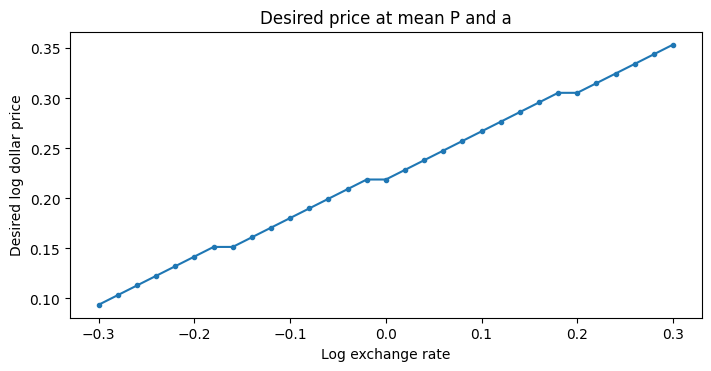

In [13]:
def desired_price(m):
    """Return the profit-maximizing dollar price at each exogenous state."""
    return m.p[np.argmax(m.Π_L, axis=0)]


index_P0 = np.argmin(np.abs(m4.P - m4.P_bar))
index_a0 = np.argmin(np.abs(m4.a))
next_P = (
    (1 - m4.α) * m4.P_bar + m4.α * m4.P[:, None]
    + (1 - m4.α) * m4.φ_bar * m4.e[None, :]
)
reconstructed_P = m4.wP * m4.P[m4.kP] + (1 - m4.wP) * m4.P[m4.kP + 1]
inside_P = (next_P >= m4.P[0]) & (next_P <= m4.P[-1])
interpolation_error = np.max(np.abs(reconstructed_P[inside_P] - next_P[inside_P]))
print(f"Maximum interpolation error inside the P grid = {interpolation_error:.3e}")

p_desired = desired_price(m4)
p_fixed = p_desired[index_P0, index_a0]
linked_nodes = np.argmin(
    np.abs(m4.P[:, None] - (m4.P_bar + m4.φ_bar * m4.e)[None, :]), axis=0
)
p_linked = p_desired[linked_nodes, index_a0, np.arange(m4.e.size)]
superelasticity = m4.ε / (m4.σ - 1)
fixed_slope = np.polyfit(m4.e, p_fixed, 1)[0]
linked_slope = np.polyfit(m4.e, p_linked, 1)[0]
print(f"Fixed P slope = {fixed_slope:.6f}, approximation = {m4.φ / (1 + superelasticity):.6f}")
print(
    f"Moving P slope = {linked_slope:.6f}, approximation = "
    f"{(m4.φ + superelasticity * m4.φ_bar) / (1 + superelasticity):.6f}"
)

fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
ax.plot(m4.e, p_fixed, "o-", markersize=3)
ax.set(xlabel="Log exchange rate", ylabel="Desired log dollar price", title="Desired price at mean P and a")
plt.show()

**(b) The expectation operator.** Arrays have axes $(p,P,a,e)$, indexed $[i,j,l,n]$, so $U$ has the shape of $\Pi_L$, $(N_p,N_P,N_a,N_e)$. Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">expect(U, m)</code> in the three steps of method 1:

$$
\begin{aligned}
U^{(a)}[i,j,l,n]&=\textstyle\sum_{l'}Q_a[l,l']\,U[i,j,l',n],\\[2pt]
U^{(P)}[i,j,l,n]&=w[j,n]\,U^{(a)}\big[i,k[j,n],l,n\big]+\big(1-w[j,n]\big)\,U^{(a)}\big[i,k[j,n]{+}1,l,n\big],\\[2pt]
\mathbb EU[i,j,l,n]&=\textstyle\sum_{n'}Q_e[n,n']\,U^{(P)}[i,j,l,n'],
\end{aligned}
$$

with $k=$ <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">m.kP</code> and $w=$ <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">m.wP</code> of shape $(N_P,N_e)$; in the second line $n$ is the index of $e'$, and $k+1$ is capped at $N_P-1$. Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">expect&#95;loop(U, m)</code>, the same expectation with explicit loops over $(p,P,a,e)$ and $(a',e')$. Then:

(i) Report the largest difference between the two on the small grid <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create&#95;gir(Np=5, NP=7, Na=3, Ne=5)</code>, for a random array $U$ of the shape of $\Pi_L$ (np.random.default_rng(0).random).

(ii) Report how many entries a full transition matrix on the exogenous state would have on the baseline grid, and its memory as a dense float64 array.

(iii) Report the time of one call of expect on the baseline grid.

In [14]:
def expect(U, m):
    """Take conditional expectations in the order a, P, e."""
    by_productivity = m.Qa @ U
    if m.P.size == 1:
        return by_productivity @ m.Qe.T

    lower = m.kP[None, :, None, :]
    upper = np.minimum(lower + 1, m.P.size - 1)
    weight = m.wP[None, :, None, :]
    at_lower = np.take_along_axis(by_productivity, lower, axis=1)
    at_upper = np.take_along_axis(by_productivity, upper, axis=1)
    at_lower *= weight
    at_upper *= 1 - weight
    at_lower += at_upper
    return at_lower @ m.Qe.T


def expect_loop(U, m):
    """Direct summation for checking the vectorized expectation on small grids."""
    result = np.zeros_like(U, dtype=float)
    for i, j, l, n in np.ndindex(U.shape):
        for l_next in range(m.a.size):
            for n_next in range(m.e.size):
                lower = m.kP[j, n_next]
                upper = min(lower + 1, m.P.size - 1)
                weight = m.wP[j, n_next]
                interpolated = (
                    weight * U[i, lower, l_next, n_next]
                    + (1 - weight) * U[i, upper, l_next, n_next]
                )
                result[i, j, l, n] += (
                    m.Qa[l, l_next] * m.Qe[n, n_next] * interpolated
                )
    return result


small_gir = create_gir(Np=5, NP=7, Na=3, Ne=5)
small_U = np.random.default_rng(0).random(small_gir.Π_L.shape)
expectation_error = np.max(np.abs(expect(small_U, small_gir) - expect_loop(small_U, small_gir)))
state_count = m4.P.size * m4.a.size * m4.e.size
entry_count = state_count**2
byte_count = entry_count * np.dtype(np.float64).itemsize
start = time.perf_counter()
baseline_expectation = expect(m4.Π_L, m4)
expect_seconds = time.perf_counter() - start
del baseline_expectation
print(f"Maximum vectorized versus loop difference = {expectation_error:.3e}")
print(f"Dense transition = {entry_count:,} entries, {byte_count:,} bytes ({byte_count / 2**30:.2f} GiB)")
print(f"One full-grid expectation = {expect_seconds:.4f} s")

Maximum vectorized versus loop difference = 3.331e-16
Dense transition = 1,216,265,625 entries, 9,730,125,000 bytes (9.06 GiB)
One full-grid expectation = 0.0601 s


**(c) Value function iteration.** With the index notation of (b), the value of resetting and the continuation values are

$$
\begin{aligned}
\bar V[j,l,n]&=\max_{c\in\{L,P\}}\ \max_i\ H_c[i,j,l,n],\\[2pt]
U_c[i,j,l,n]&=\max\big\{H_c[i,j,l,n],\ \bar V[j,l,n]-\kappa\big\},\\[2pt]
(TH)_c&=\Pi_c+\delta\ \texttt{expect}(U_c),\qquad c\in\{L,P\}.
\end{aligned}
$$

Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">bellman(H&#95;L, H&#95;P, m)</code> returning $\big((TH)_L,(TH)_P\big)$. Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">solve(m, tol=1e-6)</code> that iterates $H\leftarrow TH$ from $H_c=\Pi_c/(1-\delta)$, stops with the MacQueen-Porteus rule of method 2,

$$
\frac{\delta}{1-\delta}\,\big(\bar d-\underline d\big)<\mathrm{tol},\qquad \underline d=\min(TH-H),\ \ \bar d=\max(TH-H),
$$

where the max and min run over both arrays, and returns $(H_L,H_P)$ with the midpoint correction $\frac{\delta}{1-\delta}\frac{\bar d+\underline d}{2}$ added to $TH$ (print the number of iterations inside solve). The policies follow from the solution:

$$
\begin{aligned}
i^*_c[j,l,n]&=\arg\max_i H_c[i,j,l,n] &&\text{reset price } p^*_c=p_{i^*_c}\text{ in currency }c,\\[2pt]
c^*[j,l,n]&=\arg\max_{c}\ \max_iH_c[i,j,l,n] &&\text{currency at a reset},\\[2pt]
\text{keep}_c[i,j,l,n]&=\mathbf 1\big\{H_c[i,j,l,n]\ge\bar V[j,l,n]-\kappa\big\} &&\text{inaction region}.
\end{aligned}
$$

Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">reset&#95;policy(H&#95;L, H&#95;P, m)</code> returning $(i^*_L,i^*_P)$, each of shape $(N_P,N_a,N_e)$, and $c^*$ ($0$ for LCP, $1$ for PCP). Then:

(i) Solve the reduced model, then the full model (one Bellman step takes about 0.15 s, so about two minutes), and report iterations and run times.

(ii) For the full model, plot the reset prices $p^*_L(z)$ and $p^*_P(z)+e$ (in dollars) and the inaction band $\{p:\ \text{keep}_L[\,\cdot\,,j,l,n]=1\}$ of the LCP firm against $e$, at $P=\bar P$ and $a=0$.

Reduced model


VFI iterations = 980, bound width = 9.982e-07
Run time = 0.296 s
Full model


VFI iterations = 924, bound width = 9.806e-07
Run time = 72.301 s


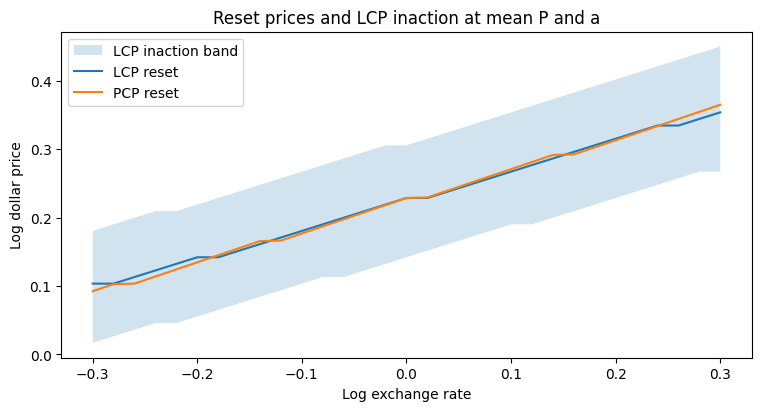

In [15]:
def bellman(H_L, H_P, m):
    """Apply the keep-or-reset Bellman operator to both currencies."""
    reset_value = np.maximum(H_L.max(axis=0), H_P.max(axis=0)) - m.κ
    update_L = m.Π_L + m.δ * expect(np.maximum(H_L, reset_value), m)
    update_P = m.Π_P + m.δ * expect(np.maximum(H_P, reset_value), m)
    return update_L, update_P


def solve(m, tol=1e-6):
    """Iterate from capitalized profits and return the midpoint of the value bounds."""
    H_L = m.Π_L / (1 - m.δ)
    H_P = m.Π_P / (1 - m.δ)
    bound_scale = m.δ / (1 - m.δ)
    for iteration in range(1, 10_001):
        next_L, next_P = bellman(H_L, H_P, m)
        change_L, change_P = next_L - H_L, next_P - H_P
        low = min(change_L.min(), change_P.min())
        high = max(change_L.max(), change_P.max())
        if bound_scale * (high - low) < tol:
            correction = bound_scale * (high + low) / 2
            print(f"VFI iterations = {iteration:,}, bound width = {bound_scale * (high - low):.3e}")
            return next_L + correction, next_P + correction
        H_L, H_P = next_L, next_P
    raise RuntimeError("Value function iteration did not reach the requested bound.")


def reset_policy(H_L, H_P, m):
    """Return reset price indices and currency codes, with LCP chosen on ties."""
    index_L = np.argmax(H_L, axis=0)
    index_P = np.argmax(H_P, axis=0)
    currency = (H_P.max(axis=0) > H_L.max(axis=0)).astype(np.int8)
    return index_L, index_P, currency


for label, model in [("Reduced model", m4r), ("Full model", m4)]:
    print(label)
    start = time.perf_counter()
    values = solve(model)
    print(f"Run time = {time.perf_counter() - start:.3f} s")
H_L_full, H_P_full = values

reset_L, reset_P, currency_full = reset_policy(H_L_full, H_P_full, m4)
reference = (index_P0, index_a0)
value_after_reset = np.maximum(H_L_full.max(axis=0), H_P_full.max(axis=0)) - m4.κ
lcp_keep = H_L_full[:, index_P0, index_a0, :] >= value_after_reset[reference]
band_lower = np.where(lcp_keep, m4.p[:, None], np.inf).min(axis=0)
band_upper = np.where(lcp_keep, m4.p[:, None], -np.inf).max(axis=0)
has_band = lcp_keep.any(axis=0)

fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
ax.fill_between(
    m4.e, np.where(has_band, band_lower, np.nan), np.where(has_band, band_upper, np.nan),
    alpha=0.2, label="LCP inaction band",
)
ax.plot(m4.e, m4.p[reset_L[reference]], label="LCP reset")
ax.plot(m4.e, m4.p[reset_P[reference]] + m4.e, label="PCP reset")
ax.set(xlabel="Log exchange rate", ylabel="Log dollar price", title="Reset prices and LCP inaction at mean P and a")
ax.legend()
plt.show()

**(d) The choice of currency.** Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">value&#95;gap(phi, eps)</code> returning $\Delta V(\phi)$ from a solve of the reduced model with $\phi$ and $\varepsilon$ as given (<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">create&#95;gir(φ=phi, ε=eps, reduced=True)</code>). Then:

(i) Find $\phi^*$ with brentq on $[0.3,1.2]$ (<code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">xtol=1e-4</code>) for $\varepsilon=3$ ($\Gamma=0.75$) and $\varepsilon=0$ (CES, $\Gamma=0$); each root takes about ten seconds. Report each $\phi^*$ next to $(1+\Gamma)/2$, the $\phi$ at which the flexible-price pass-through $\phi/(1+\Gamma)$ equals one half.

(ii) Plot $c^*(z)$ over $(a,e)$ for the reduced model at $\phi^*\pm0.1$ ($\varepsilon=3$), for example with plt.pcolormesh.

Root search at epsilon = 3


VFI iterations = 936, bound width = 9.889e-07


VFI iterations = 1,003, bound width = 9.906e-07


VFI iterations = 987, bound width = 9.822e-07


VFI iterations = 988, bound width = 9.821e-07


VFI iterations = 988, bound width = 9.821e-07
Indifference phi = 0.870763, flexible-price benchmark = 0.875000
Root search at epsilon = 0


... (5 outputs left out)

VFI iterations = 983, bound width = 9.855e-07


VFI iterations = 983, bound width = 9.856e-07
Indifference phi = 0.468559, flexible-price benchmark = 0.500000


VFI iterations = 982, bound width = 9.843e-07


VFI iterations = 993, bound width = 9.869e-07


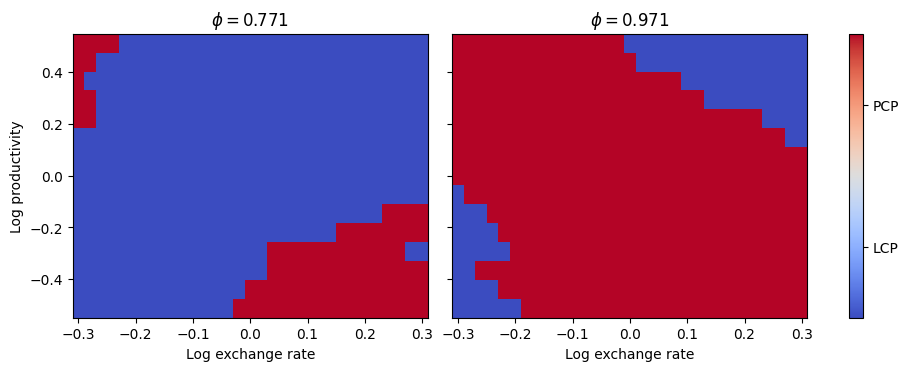

In [16]:
def value_gap(phi, eps):
    """Find the LCP minus PCP maximized value at the reduced model's mean state."""
    model = create_gir(φ=phi, ε=eps, reduced=True)
    H_L, H_P = solve(model)
    reference = (0, model.a.size // 2, model.e.size // 2)
    return H_L[(slice(None),) + reference].max() - H_P[(slice(None),) + reference].max()


currency_roots = {}
for eps in (3.0, 0.0):
    print(f"Root search at epsilon = {eps:g}")
    root = brentq(value_gap, 0.3, 1.2, args=(eps,), xtol=1e-4)
    currency_roots[eps] = root
    benchmark = (1 + eps / (m4.σ - 1)) / 2
    print(f"Indifference phi = {root:.6f}, flexible-price benchmark = {benchmark:.6f}")

phi_star = currency_roots[3.0]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True, layout="constrained")
for ax, phi in zip(axes, (phi_star - 0.1, phi_star + 0.1)):
    model = create_gir(φ=phi, reduced=True)
    _, _, choice = reset_policy(*solve(model), model)
    mesh = ax.pcolormesh(
        model.e, model.a, choice[0], shading="nearest", cmap="coolwarm", vmin=0, vmax=1
    )
    ax.set(xlabel="Log exchange rate", title=fr"$\phi={phi:.3f}$")
axes[0].set_ylabel("Log productivity")
colorbar = fig.colorbar(mesh, ax=axes, ticks=[0.25, 0.75])
colorbar.ax.set_yticklabels(["LCP", "PCP"])
plt.show()

**(e) Price changes.** Write <code style="color:#555;background:#f3f3f3;padding:1px 4px;border-radius:3px">simulate&#95;firms(H&#95;L, H&#95;P, m, N=5000, T=600, seed=0)</code>, vectorized across firms, using the full-model solution of (c). Start all firms at $z_0$ with currency $c^*(z_0)$ and price $p^*_{c^*(z_0)}(z_0)$. Each month, for each firm:

1. draw $a'$ and $e'$ independently across firms from the rows of $Q_a$ and $Q_e$ by the inverse CDF (np.random.default_rng(seed)); each firm has its own exchange-rate path, and therefore its own sector price;
2. move $P$ to node $k(P,e')$ with probability $w(P,e')$ and to node $\min(k+1,N_P-1)$ otherwise;
3. keep the price and currency if $H_c(p,z')\ge\bar V(z')-\kappa$; otherwise reset to $\big(c^*(z'),\,p^*_{c^*(z')}(z')\big)$.

Return arrays of shape $(T,N)$ with the dollar price ($p$ under LCP, $p+e$ under PCP), the currency, the exchange rate, and a reset indicator. A *price change* is a reset. Then:

(i) Drop the first 120 months and report the monthly frequency of price changes, the median duration of a price (months between consecutive changes, completed spells only), the mean absolute size of changes in dollar prices, $|p^{\rm usd}_{\rm new}-p^{\rm usd}_{\rm old}|$ with the old price valued at the same month's $e$ ($p_{\rm old}$ under LCP, $p_{\rm old}+e$ under PCP), and the share of firm-months in LCP.

(ii) Plot, in one figure with three panels: the histogram of the dollar price changes $p^{\rm usd}_{\rm new}-p^{\rm usd}_{\rm old}$ after the first 120 months, separately for LCP and PCP firms; the histogram of the durations of completed price spells, with the median marked; and, for months 120 to 240, the dollar price and the exchange rate of one firm in LCP and one firm in PCP throughout that window.

Monthly reset frequency = 14.4930%
Median completed spell = 5 months (342,832 spells)
Mean absolute log dollar reset change = 0.115567
LCP share of firm-months = 89.3996%
Example LCP firm = 0 (zero-based index, seed = 0)


Example PCP firm = 1385 (zero-based index, seed = 134)


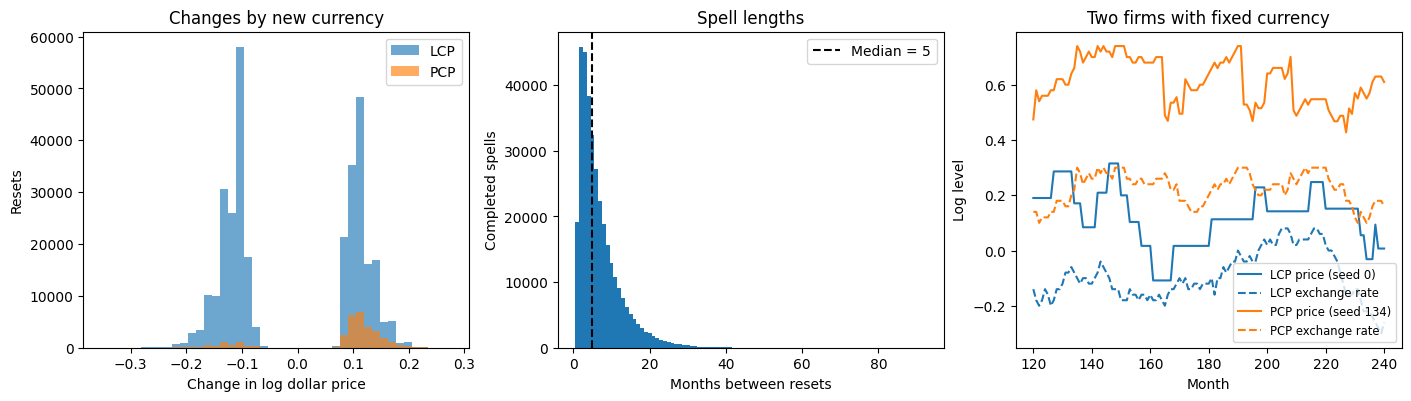

In [17]:
def draw_markov(cdf, current, rng):
    """Sample the next state independently for each firm by inverse CDF."""
    return np.sum(rng.random(current.size)[:, None] >= cdf[current], axis=1)


def simulate_firms(H_L, H_P, m, N=5000, T=600, seed=0):
    """Simulate dollar prices, currencies, exchange rates and resets."""
    rng = np.random.default_rng(seed)
    cdf_a = np.cumsum(m.Qa, axis=1)
    cdf_e = np.cumsum(m.Qe, axis=1)
    cdf_a[:, -1] = 1.0
    cdf_e[:, -1] = 1.0
    index_L, index_P, reset_currency = reset_policy(H_L, H_P, m)
    reset_value = np.maximum(H_L.max(axis=0), H_P.max(axis=0)) - m.κ

    # Row zero records the initial contract. Transitions start in month one.
    sector = np.full(N, m.P.size // 2, dtype=int)
    productivity = np.full(N, m.a.size // 2, dtype=int)
    exchange = np.full(N, m.e.size // 2, dtype=int)
    state = (sector, productivity, exchange)
    currency = reset_currency[state]
    price = np.where(currency == 0, index_L[state], index_P[state])
    usd = np.empty((T, N))
    currency_panel = np.empty((T, N), dtype=np.int8)
    exchange_panel = np.empty((T, N))
    resets = np.zeros((T, N), dtype=bool)

    for month in range(T):
        if month:
            productivity = draw_markov(cdf_a, productivity, rng)
            exchange = draw_markov(cdf_e, exchange, rng)
            lower = m.kP[sector, exchange]
            use_upper = rng.random(N) >= m.wP[sector, exchange]
            sector = np.minimum(lower + use_upper, m.P.size - 1)
            state = (sector, productivity, exchange)
            old_state = (price,) + state
            keep_value = np.where(currency == 0, H_L[old_state], H_P[old_state])
            change = keep_value < reset_value[state]
            chosen_currency = reset_currency[state]
            chosen_price = np.where(chosen_currency == 0, index_L[state], index_P[state])
            currency = np.where(change, chosen_currency, currency)
            price = np.where(change, chosen_price, price)
            resets[month] = change

        e_today = m.e[exchange]
        usd[month] = m.p[price] + (currency == 1) * e_today
        currency_panel[month] = currency
        exchange_panel[month] = e_today
    return usd, currency_panel, exchange_panel, resets


def consecutive_resets(resets, burn_in):
    """Return the firm and both dates for every consecutive post-burn-in reset pair."""
    firms, months = np.nonzero(resets[burn_in:].T)
    months += burn_in
    same_firm = firms[1:] == firms[:-1]
    return firms[1:][same_firm], months[:-1][same_firm], months[1:][same_firm]


burn_in = 120
usd, currency, exchange, resets = simulate_firms(H_L_full, H_P_full, m4)
firms, month = np.nonzero(resets[burn_in:].T)
month += burn_in
old_usd_at_new_e = usd[month - 1, firms] + (currency[month - 1, firms] == 1) * (
    exchange[month, firms] - exchange[month - 1, firms]
)
reset_changes = usd[month, firms] - old_usd_at_new_e
new_currency = currency[month, firms]
_, earlier, later = consecutive_resets(resets, burn_in)
durations = later - earlier
median_duration = np.median(durations)
print(f"Monthly reset frequency = {resets[burn_in:].mean():.4%}")
print(f"Median completed spell = {median_duration:g} months ({durations.size:,} spells)")
print(f"Mean absolute log dollar reset change = {np.abs(reset_changes).mean():.6f}")
print(f"LCP share of firm-months = {np.mean(currency[burn_in:] == 0):.4%}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), layout="constrained")
bins = np.linspace(reset_changes.min(), reset_changes.max(), 45)
for code, label in enumerate(("LCP", "PCP")):
    axes[0].hist(reset_changes[new_currency == code], bins=bins, alpha=0.65, label=label)
axes[0].set(xlabel="Change in log dollar price", ylabel="Resets", title="Changes by new currency")
axes[0].legend()
axes[1].hist(durations, bins=np.arange(0.5, durations.max() + 1.5), color="tab:blue")
axes[1].axvline(median_duration, color="black", linestyle="--", label=f"Median = {median_duration:g}")
axes[1].set(xlabel="Months between resets", ylabel="Completed spells", title="Spell lengths")
axes[1].legend()

example_months = np.arange(120, 241)
for code, label in enumerate(("LCP", "PCP")):
    example_usd, example_currency, example_e = usd, currency, exchange
    example_seed = 0
    candidates = np.flatnonzero(np.all(example_currency[example_months] == code, axis=0))
    if code == 1 and not candidates.size:
        # Seed 134 supplies the PCP illustration when seed 0 has no such firm.
        # The reported statistics and histograms use seed 0.
        example_seed = 134
        example_usd, example_currency, example_e, _ = simulate_firms(
            H_L_full, H_P_full, m4, seed=example_seed
        )
        candidates = np.flatnonzero(np.all(example_currency[example_months] == code, axis=0))

    if candidates.size:
        firm = candidates[0]
        line, = axes[2].plot(
            example_months, example_usd[example_months, firm], label=f"{label} price (seed {example_seed})"
        )
        axes[2].plot(
            example_months, example_e[example_months, firm], linestyle="--",
            color=line.get_color(), label=f"{label} exchange rate",
        )
        print(f"Example {label} firm = {firm} (zero-based index, seed = {example_seed})")
    else:
        print(f"No firm in {label} throughout months 120–240 in the illustration panels.")
axes[2].set(xlabel="Month", ylabel="Log level", title="Two firms with fixed currency")
axes[2].legend(fontsize="small")
plt.show()

**(f) Pass-through.** In simulated data, regress by OLS (np.polyfit) the change in the dollar price between consecutive price changes of a firm on the change in the exchange rate over the same interval,

$$
\Delta p^{\rm usd}_{\rm change}=\beta_0+\beta_1\,\Delta e_{\rm since\ last\ change}+u,
$$

separately for LCP and PCP firms, where $\Delta p^{\rm usd}$ is the dollar price set at this change minus the dollar price set at the previous change, $\Delta e$ is the change in $e$ between the two dates, and a pair is kept if the firm has the same currency after both changes. Use the reduced model at $\phi=\phi^*-0.15$ and $\phi=\phi^*+0.15$ (with $\phi^*$ from (d), $\varepsilon=3$), simulated as in (e) (same $N$, $T$ and seed, dropping the first 120 months). Then:

(i) Report $\beta_1$ for LCP and PCP firms at each $\phi$, with the number of pairs.

(ii) Report the currency that (d) predicts at each $\phi$ next to the simulated share of firm-months in LCP.

In [18]:
for phi in (phi_star - 0.15, phi_star + 0.15):
    model = create_gir(φ=phi, reduced=True)
    H_L, H_P = solve(model)
    simulated_usd, simulated_currency, simulated_e, simulated_resets = simulate_firms(H_L, H_P, model)
    firms, earlier, later = consecutive_resets(simulated_resets, burn_in)
    currency_earlier = simulated_currency[earlier, firms]
    currency_later = simulated_currency[later, firms]
    delta_usd = simulated_usd[later, firms] - simulated_usd[earlier, firms]
    delta_e = simulated_e[later, firms] - simulated_e[earlier, firms]
    _, _, choice = reset_policy(H_L, H_P, model)
    predicted_currency = ("LCP", "PCP")[choice[0, model.a.size // 2, model.e.size // 2]]
    fraction_lcp = np.mean(simulated_currency[burn_in:] == 0)

    print(f"phi = {phi:.6f}, mean-state choice = {predicted_currency}, LCP share = {fraction_lcp:.4%}")
    for code, label in enumerate(("LCP", "PCP")):
        selected = (currency_earlier == code) & (currency_later == code)
        count = np.count_nonzero(selected)
        if count >= 2 and np.ptp(delta_e[selected]) > 0:
            slope = np.polyfit(delta_e[selected], delta_usd[selected], 1)[0]
            print(f"  {label} slope = {slope:.6f} ({count:,} reset pairs)")
        else:
            print(f"  {label} slope is unidentified ({count:,} reset pairs)")

VFI iterations = 978, bound width = 9.998e-07


phi = 0.720763, mean-state choice = LCP, LCP share = 92.9665%
  LCP slope = 0.429311 (302,233 reset pairs)
  PCP slope = 0.911147 (2,560 reset pairs)


VFI iterations = 995, bound width = 9.954e-07


phi = 1.020763, mean-state choice = PCP, LCP share = 3.2625%
  LCP slope = 1.498668 (3,191 reset pairs)
  PCP slope = 0.523535 (315,334 reset pairs)
